# Member-state statements: extraction pipeline

**Milestone 1:** one clean table of member-state statements from GA sessions 80 and 81 (plenary + Main Committees), with statistics and windows.
Retrieval (statement ↔ resolution / subject) comes afterwards and is out of scope here.

Steps:

1. Load the raw data (transcripts.un.org archive + ODS PVs)
2. Coverage table: which meetings do we have, and from which source?
3. Parse both sources into one statement schema
4. Statistics
5. Sentence splitting + windows

Kernel: the repo's uv environment (`.venv`). Add packages with `uv add <pkg>`; the notebook expects VS Code's default working directory (this folder) for the paths below.

In [90]:
from pathlib import Path

import pandas as pd

In [29]:
DATA = Path.cwd().parents[2] / "data"
TRANSCRIPTS = DATA / "transcripts"  # {slug}.json.gz + index.jsonl, written by archive_transcripts.py
ODS = DATA / "session80"  # meeting_records.jsonl (text per page) + pdf/
SESSIONS = {80, 81}

In [30]:
DATA

PosixPath('/home/janic/Workspace/Personal/repos/policy-pulse/data')

## 0a. transcripts.un.org API

A quick overview how we can fetch meeting record transcripts from the website

In [31]:
from transcripts_api import *

In [32]:
BASE = "https://transcripts.un.org"
OUT = DATA / "examples"
if not OUT.exists():
    OUT.mkdir()

In [33]:
GA_BODIES = {"General Assembly"} | {
    f"{n} Committee" for n in ("First", "Second", "Third", "Fourth", "Fifth", "Sixth")
}

In [34]:
import requests
http = requests.Session()
DATE = "2026-06-30" # Choose a date to get the meeting records from 

In [97]:
resp = http.get(f"{BASE}/en/meetings.json", params={"date": DATE}, timeout=120)
resp.raise_for_status()
body = resp.json()
meetings = body["meetings"]

In [98]:
meetings

[{'title': 'UN Geneva Press Briefing: HRC, UNDP, UNHCR, UNCTAD, UNECE',
  'date': '2026-06-30T00:00:00.000Z',
  'body': None,
  'category': 'Press Conferences',
  'slug': 'briefing/geneva/2026-06-30',
  'duration': '00:54:29',
  'hasTranscript': True,
  'pageUrl': '/en/briefing/geneva/2026-06-30',
  'jsonUrl': '/en/briefing/geneva/2026-06-30.json',
  'textUrl': '/en/briefing/geneva/2026-06-30.txt'},
 {'title': '(Part 1) UNRWA Pledging Conference 2026',
  'date': '2026-06-30T00:00:00.000Z',
  'body': None,
  'category': 'Conferences',
  'slug': 'asset/k17/k17lxc4l2b',
  'duration': '02:55:07',
  'hasTranscript': True,
  'pageUrl': '/en/asset/k17/k17lxc4l2b',
  'jsonUrl': '/en/asset/k17/k17lxc4l2b.json',
  'textUrl': '/en/asset/k17/k17lxc4l2b.txt'},
 {'title': 'Palestine, Venezuela, South Sudan & other topics - Daily Press Briefing',
  'date': '2026-06-30T00:00:00.000Z',
  'body': None,
  'category': 'Press Conferences',
  'slug': 'briefing/sg/2026-06-30',
  'duration': '00:23:03',
  'ha

In [99]:
# only take ga meeting records
ga_meetings = [m for m in meetings if "ga" in m["slug"]]
ga_meetings

[{'title': 'Fifth Committee, 33rd plenary meeting - General Assembly, Second part of the resumed 80th session',
  'date': '2026-06-30T00:00:00.000Z',
  'body': 'Fifth Committee',
  'category': 'General Assembly',
  'slug': 'ga/c5/80/33',
  'duration': '01:55:52',
  'hasTranscript': True,
  'pageUrl': '/en/ga/c5/80/33',
  'jsonUrl': '/en/ga/c5/80/33.json',
  'textUrl': '/en/ga/c5/80/33.txt'},
 {'title': 'General Assembly: 94th plenary meeting, 80th session',
  'date': '2026-06-30T00:00:00.000Z',
  'body': 'General Assembly',
  'category': 'General Assembly',
  'slug': 'ga/80/94',
  'duration': '00:54:22',
  'hasTranscript': True,
  'pageUrl': '/en/ga/80/94',
  'jsonUrl': '/en/ga/80/94.json',
  'textUrl': '/en/ga/80/94.txt'}]

In [100]:
import json
# Fetch a ga meetign record transcripts
ga_mr = ga_meetings[0]
resp = http.get(f"{BASE}{ga_mr['jsonUrl']}", timeout=120)
resp.raise_for_status()

ga_mr_content = MeetingResponse.model_validate_json(resp.content)

In [101]:
# Some information about the content
print(f"Disclaimer:\n{ga_mr_content.disclaimer}")

Disclaimer:
Transcripts available through this tool are created by using automatic speech recognition and are not official records nor official documents of the United Nations. Official records and official documents are available on the Official Document System of the United Nations.


In [102]:
# Look at a transcript information
ga_mr_transcripts  = ga_mr_content.transcript
assert ga_mr_transcripts is not None
print(f"Keys in transcripts:\n{ga_mr_transcripts.model_fields_set}")
print(f"Transcript_id:\n{ga_mr_transcripts.transcript_id}")
print(f"Language:\n{ga_mr_transcripts.language}")
print(f"Topics:\n{ga_mr_transcripts.topics}") 

Keys in transcripts:
{'language', 'topics', 'transcript_id', 'data'}
Transcript_id:
azure-llm-speech-36e82d49-bf3c-4a51-be47-d852d88ee13f
Language:
en
Topics:
[Topic(key='tcc-pcc-reimbursement', label='Reimbursement for Troop and Police Contributors', description='Several statements addressed reimbursement rates for troop- and police-contributing countries and the standards for contingent-owned equipment. This was framed as recognition of the costs, responsibilities, and sacrifices borne by countries that provide personnel and equipment to UN peacekeeping.'), Topic(key='assessed-contributions', label='Assessed Contributions and Arrears', description="Many speakers stressed that the underlying cause of the UN's financial strain is late or unpaid assessed contributions. They emphasized the Charter obligation to pay in full, on time, and without conditions, while some also raised the impact of sanctions and banking constraints on payments."), Topic(key='peacekeeping-financing', label='Pea

In [103]:
# Look at the actual data in transcripts
from rich.pretty import pprint
assert ga_mr_transcripts is not None
ga_mr_data : list[Statement] =  ga_mr_transcripts.data
print(f"Num records in data: {len(ga_mr_data)}")
print("First Statement of data:")
pprint(ga_mr_data[0], max_length=2, max_string=80)

Num records in data: 51
First Statement of data:


Statement(
│   statement_number=1,
│   start=0.11,
│   paragraphs=[
│   │   Paragraph(
│   │   │   sentences=[
│   │   │   │   Sentence(
│   │   │   │   │   text='I call to order the 33rd meeting of the Fifth Committee at the second part of ou'+23,
│   │   │   │   │   start=0.11,
│   │   │   │   │   end=6.83,
│   │   │   │   │   topics=[]
│   │   │   │   ),
│   │   │   │   Sentence(
│   │   │   │   │   text='Distinguished delegates, we turn our attention to action on draft resolutions on'+94,
│   │   │   │   │   start=10.75,
│   │   │   │   │   end=21.07,
│   │   │   │   │   topics=[]
│   │   │   │   ),
│   │   │   │   ... +18
│   │   │   ]
│   │   )
│   ],
│   speaker=Speaker(affiliation='5th Committee', affiliation_full='5th Committee', group=None, function='Chair')
)

In [104]:
# Let's look at a paragraph
stmnt : Statement = ga_mr_data[0]
print(f"Number of paragraphs in first statement: {len(stmnt.paragraphs)}")
print(f"First paragraph Keys:\n{stmnt.model_fields_set}")
print(f"Number of sentences in first paragraph:\n{len(stmnt.paragraphs[0].sentences)}")
print("First sentence")
pprint(stmnt.paragraphs[0].sentences[0])

Number of paragraphs in first statement: 1
First paragraph Keys:
{'start', 'statement_number', 'paragraphs', 'speaker'}
Number of sentences in first paragraph:
20
First sentence


Sentence(
│   text='I call to order the 33rd meeting of the Fifth Committee at the second part of our resumed 80th session.',
│   start=0.11,
│   end=6.83,
│   topics=[]
)

In [105]:
# TODO: write the concrete fetcher and archiver here too!
# Probably its best to write the code in transcripts_api.py (rename it!) and then import it here!

## 0b. Fetching data from ODS

This section shows some examples on how we fetch official meeting records from ODS


In [106]:
# Config
MARC_BIBS = "https://metadata.un.org/editor/api/marc/bibs/records"
ODS_ACCESS = "https://documents.un.org/api/symbol/access"
ODS = DATA / "ods"
ODS.mkdir(parents=True, exist_ok=True)
PDF_DIR = ODS / "pdf"
PDF_DIR.mkdir(parents=True, exist_ok=True)

In [107]:
from pydantic import BaseModel, Field, ValidationError


class MARCEntry(BaseModel):
    _id: int
    # agendas: seems empty?
    # basket: empty too
    date: str # TODO: again could be better
    f520: list[str] # TODO: check what this contains
    symbol: str
    title: str
    types: str # Currently only interested in meeting records
    url: str

    
class MARCSearchMeta(BaseModel):
    count: int
    name: str
    timestamp: str # TODO: there is probably a better type for this

class MARCSearchResponse(BaseModel):
    _meta: MARCSearchMeta
    data: list[MARCEntry]

In [108]:
resp = http.get(MARC_BIBS, params={"search": "191__c:80", "subtype": "all", "format": "brief", "sort":"date", "direction":"desc", "limit":1000}, timeout=120)
resp.raise_for_status()

marc_search = MARCSearchResponse.model_validate_json(resp.content)

pprint(marc_search, max_length=5, max_string=80)

MARCSearchResponse(
│   data=[
│   │   MARCEntry(
│   │   │   date='2026-10-14',
│   │   │   f520=[''],
│   │   │   symbol='A/C.2/80/SR.13; E/2026/SR.3',
│   │   │   title='Summary record of the joint meeting of the Second Committee and the Economic and'+305,
│   │   │   types='Documents and Publications::Meeting Records::Summary Records',
│   │   │   url='https://metadata.un.org/editor/api/marc/bibs/records/1477503'
│   │   ),
│   │   MARCEntry(
│   │   │   date='2026-11-11',
│   │   │   f520=[''],
│   │   │   symbol='A/C.4/81/L.13',
│   │   │   title="Palestine refugees' properties and their revenues : draft resolution / Algeria, "+186,
│   │   │   types='Documents and Publications::Draft Resolutions and Decisions',
│   │   │   url='https://metadata.un.org/editor/api/marc/bibs/records/1478018'
│   │   ),
│   │   MARCEntry(
│   │   │   date='2026-11-11',
│   │   │   f520=[''],
│   │   │   symbol='A/C.4/81/L.12',
│   │   │   title='Operations of the United Nations Relief and Works Agency for Palestine Refugees '+254,
│   │   │   types='Documents and Publications::Draft Resolutions and Decisions',
│   │   │   url='https://metadata.un.org/editor/api/marc/bibs/records/1478017'
│   │   ),
│   │   MARCEntry(
│   │   │   date='2026-09-08',
│   │   │   f520=['Contains statement delivered by the President of the State of Palestine, on 25 S'+66],
│   │   │   symbol='A/80/825',
│   │   │   title='Note / by the President of the General Assembly',
│   │   │   types='Documents and Publications',
│   │   │   url='https://metadata.un.org/editor/api/marc/bibs/records/1474384'
│   │   ),
│   │   MARCEntry(
│   │   │   date='2026-09-08',
│   │   │   f520=['Refutes allegations in memorandum dated 7 Aug. 2026 from the United Arab Emirate'+112],
│   │   │   symbol='A/80/826; S/2026/708',
│   │   │   title='Note verbale dated 8 September 2026 from the Permanent Mission of the Sudan to t'+52,
│   │   │   types='Documents and Publications::Letters and Notes Verbales',
│   │   │   url='https://metadata.un.org/editor/api/marc/bibs/records/1474183'
│   │   ),
│   │   ... +995
│   ]
)

In [109]:
pprint(marc_search.data[4], max_length=13, max_string=80)

MARCEntry(
│   date='2026-09-08',
│   f520=['Refutes allegations in memorandum dated 7 Aug. 2026 from the United Arab Emirate'+112],
│   symbol='A/80/826; S/2026/708',
│   title='Note verbale dated 8 September 2026 from the Permanent Mission of the Sudan to t'+52,
│   types='Documents and Publications::Letters and Notes Verbales',
│   url='https://metadata.un.org/editor/api/marc/bibs/records/1474183'
)

In [110]:
# Let's get a meeting record example
# TODO: I am pretty sure that we can directly embedd this in the query 
entry = [entry for entry in marc_search.data if entry.types == 'Documents and Publications::Meeting Records::Verbatim Records'][0]
entry

MARCEntry(date='2025-09-23', f520=[''], symbol='A/80/PV.4', title='General Assembly official records, 80th session : 4th plenary meeting, Tuesday, 23 September 2025, New York', types='Documents and Publications::Meeting Records::Verbatim Records', url='https://metadata.un.org/editor/api/marc/bibs/records/1475235')

Currently we are keeping an archive of these transcripts, in the following we continue to work using the downloaded archives.
Extension: We can maybe even explore the topics that are assigned through the transcription module

In [111]:
# Let's get the record and save it in our pdf path
import re

def _out_path(symbol: str) -> Path:
    return PDF_DIR / (re.sub(r"[^A-Za-z0-9.]+", "_", symbol).strip("_") + ".pdf")

entry_path = _out_path(entry.symbol)

if entry_path.exists():
    # Delete it for showcase
    entry_path.unlink()
    print("already downloaded, deleted to redownload")

resp = http.get(ODS_ACCESS, params={"s": entry.symbol, "l": "en", "t": "pdf"}, timeout=120)
resp.raise_for_status()

if not resp.headers.get("content-type", "").startswith("application/pdf"):
    # File not available on ODS
    print(f"{entry.symbol} not on ODS!")
    assert False

entry_path.write_bytes(resp.content)

already downloaded, deleted to redownload


734066

In [136]:
class MeetingRecordPDF(BaseModel):
    symbol: str
    #path: Path | None
    title: str | None
    pdf_created: str | None
    n_pages: int
    n_chars: int
    file: str
    pages: list

In [ ]:
# Success! Let's parse it now to extract the actual statements
import pymupdf

with pymupdf.open(entry_path) as doc:
    pages = [page.get_text() for page in doc]
    meta = doc.metadata or {}

mr_pdf = MeetingRecordPDF(
    symbol=entry.symbol,
    #path=entry_path,
    title=meta.get("title"),
    pdf_created = meta.get("creationDate"),
    n_pages=len(pages),
    n_chars=sum(len(p) for p in pages),
    file=entry_path.name,
    pages=pages   
)

pprint(mr_pdf, max_length=10, max_string=80)

MeetingRecordPDF(
│   symbol='A/80/PV.4',
│   path=PosixPath('/home/janic/Workspace/Personal/repos/policy-pulse/data/ods/pdf/A_80_PV.4.pdf'),
│   title='General Assembly Eightieth session 4th plenary meeting Tuesday, 23 September 202'+18,
│   pdf_created="D:20261006120000-04'00'",
│   n_pages=74,
│   n_chars=285291,
│   file='A_80_PV.4.pdf',
│   pages=[
│   │   'United Nations \nA/80/PV.4\n \n \nGeneral Assembly \nEightieth session \n4th plenary m'+2771,
│   │   'A/80/PV.4 \n23/09/2025\n \n25-15238\n2/74 \n \nWe have our work cut out for us, as our'+4038,
│   │   '23/09/2025 \nA/80/PV.4\n \n3/74\n25-15238 \n \nkilling has intensified. The measures s'+4014,
│   │   'A/80/PV.4 \n23/09/2025\n \n25-15238\n4/74 \n \nrepresent today’s world, with far great'+3813,
│   │   '23/09/2025 \nA/80/PV.4\n \n5/74\n25-15238 \n \nWe need universal guardrails and common'+4075,
│   │   'A/80/PV.4 \n23/09/2025\n \n25-15238\n6/74 \n \nfor dignity, for justice, for humanity,'+4050,
│   │   '23/09/2025 \nA/80/PV.4\n \n7/74\n25-15238 \n \nsummon again the strength and unity fir'+4248,
│   │   'A/80/PV.4 \n23/09/2025\n \n25-15238\n8/74 \n \nspeakers to be heard at a given meeting'+3759,
│   │   '23/09/2025 \nA/80/PV.4\n \n9/74\n25-15238 \n \nwas secured, a prerogative that dictato'+4317,
│   │   'A/80/PV.4 \n23/09/2025\n \n25-15238\n10/74 \n \nindefensible from any angle. But nothi'+4177,
│   │   ... +64
│   ]
)

In [114]:
# Let's look at a complete page
print(mr_pdf.pages[0])

United Nations 
A/80/PV.4
 
 
General Assembly 
Eightieth session 
4th plenary meeting 
Tuesday, 23 September 2025, 9 a.m. 
New York 
Official Records
 
 
 
This record contains the text of speeches delivered in English and of the translation of speeches 
delivered in other languages. Corrections should be submitted to the original languages only. 
They should be incorporated in a copy of the record and sent under the signature of a member of 
the delegation concerned to the Chief of the Verbatim Reporting Service, room AB-0928 
(verbatimrecords@un.org). Corrected records will be reissued electronically on the Official 
Document System of the United Nations (http://documents.un.org). 
 
 
 
25-15238 (E) 
 
 
 
President:  
Ms. Baerbock ....................................................................................................... (Germany) 
The meeting was called to order at 9.05 a.m. 
Agenda item 110 
Report of the Secretary-General on the work of the Organization (A/80/1) 
Th

In [115]:
# Some patterns that we already see
# 1. Header/Footer repeats on each page
# 2. Agenda Items are introduced on a separate line e.g. "Agenda Item {nn}" the title of the agenda item follows subsequently
# 3. Speakers are introduced using a speaker label (The President, The Secretary-General, etc.)

In [116]:
# 1. Clean headers and footers on each page

HEADER_RE = re.compile(r"^\s*(?:A/\S+|\d{2}/\d{2}/\d{4}|\d{2}-\d{5}(?: \(E\))?|\d+/\d+|\*\d+\*)?\s*$")

def clean_and_combine(pages: list[str]) -> str:
    text = "\n".join(l for p in pages for l in p.splitlines() if not HEADER_RE.match(l))
    start = text.find("The meeting was called to order") # Opening the Meeting
    end = text.rfind("The meeting rose at") # Closing the Meeting
    return text[max(start, 0) : end if end >= 0 else len(text)]

complete_speeches = clean_and_combine(mr_pdf.pages)
print(complete_speeches[:1000]) 

The meeting was called to order at 9.05 a.m. 
Agenda item 110 
Report of the Secretary-General on the work of the Organization (A/80/1) 
The President: Before proceeding to the general debate, the General Assembly 
will hear an introduction by the Secretary-General of his annual report (A/80/1) on the 
work of the Organization, under agenda item 110, in accordance with resolution 51/241 
of 31 July 1997.  
I now give the floor to His Excellency Secretary-General António Guterres.  
The Secretary-General: Let me begin with two words we have not been able to 
say often enough in this Hall: Madam President. 
Eighty years ago, in a world scorched by war, leaders made a choice: cooperation 
over chaos, law over lawlessness and peace over conflict. That choice gave birth to the 
United Nations, not as a dream for perfection, but as a practical strategy for the survival 
of humanity. Many of our founders had seen first-hand the hell of the death camps and 
the terror of war. They knew that tr

In [117]:
# Figuring out when a new agenda started
AGENDA_RE = re.compile(
    r"^Agenda items? (?P<agenda>\d+)[^\n]*$"                                  # "Agenda item 13 (continued)"
    r"|^Address by (?P<address>(?s:.+?))\s*(?=^(?:The|Mr\.|Ms\.|Mrs\.) )",    # may wrap over 2 lines
    re.M,
)

agendas = [(m.start(), m.end(), "heading", m) for m in AGENDA_RE.finditer(complete_speeches)]

print(len(agendas))
pprint(agendas, max_length=5)


18


[
│   (46, 62, 'heading', <re.Match object; span=(46, 62), match='Agenda item 110 '>),
│   (18276, 18290, 'heading', <re.Match object; span=(18276, 18290), match='Agenda item 8 '>),
│   (
│   │   27602,
│   │   27693,
│   │   'heading',
│   │   <re.Match object; span=(27602, 27693), match='Address by Mr. Luiz Inácio Lula da Silva, Preside>
│   ),
│   (
│   │   40273,
│   │   40348,
│   │   'heading',
│   │   <re.Match object; span=(40273, 40348), match='Address by Mr. Donald J. Trump, President of the >
│   ),
│   (
│   │   88003,
│   │   88076,
│   │   'heading',
│   │   <re.Match object; span=(88003, 88076), match='Address by Mr. Prabowo Subianto, President of the>
│   ),
│   ... +13
]

In [118]:
# How speakers are introduced
SPEAKER_RE = re.compile(r"""
^(?P<label>
    The\ (?:Acting\ )?(?:President|Chair|Secretary-General|Vice-President)
  | (?:Mr|Ms|Mrs|Miss|Dame|Sir)\.?\ [^\n():]{1,60}?\ \((?P<affiliation>[^)]+)\)
  | (?:President|Prime\ Minister|King|Queen|Emir|Sheikh|Crown\ Prince|Prince|Vice-President|Chancellor)\ [^\n():]{1,60}?
)
(?:\ \(spoke\ in\ (?P<lang>\w+)[^)]*\))?
:\s
""", re.M | re.X)

speakers = [(m.start(), m.end(), "speaker", m) for m in SPEAKER_RE.finditer(complete_speeches)]

print(len(speakers))
pprint(speakers, max_length=5)

68


[
│   (137, 152, 'speaker', <re.Match object; span=(137, 152), match='The President: '>),
│   (487, 510, 'speaker', <re.Match object; span=(487, 510), match='The Secretary-General: '>),
│   (18211, 18226, 'speaker', <re.Match object; span=(18211, 18226), match='The President: '>),
│   (18307, 18322, 'speaker', <re.Match object; span=(18307, 18322), match='The President: '>),
│   (27215, 27230, 'speaker', <re.Match object; span=(27215, 27230), match='The President: '>),
│   ... +63
]

In [119]:
# Information about who is escorted to and from the General Assembly Hall
STAGE_RE = re.compile(
    r"^(?:Mr|Ms|Mrs)\. [^:]{0,200}?was\s+escorted\s+(?:into|from)\s+the\s+General\s+Assembly\s+Hall\.", re.M
)

stages = [(m.start(), m.end(), "stage", m) for m in STAGE_RE.finditer(complete_speeches)]

print(len(stages))
pprint(stages, max_length=5)

24


[
│   (
│   │   27803,
│   │   27927,
│   │   'stage',
│   │   <re.Match object; span=(27803, 27927), match='Mr. Luiz Inácio Lula da Silva, President of the F>
│   ),
│   (
│   │   40147,
│   │   40271,
│   │   'stage',
│   │   <re.Match object; span=(40147, 40271), match='Mr. Luiz Inácio Lula da Silva, President of the F>
│   ),
│   (
│   │   40453,
│   │   40562,
│   │   'stage',
│   │   <re.Match object; span=(40453, 40562), match='Mr. Donald J. Trump, President of the United Stat>
│   ),
│   (
│   │   87660,
│   │   87769,
│   │   'stage',
│   │   <re.Match object; span=(87660, 87769), match='Mr. Donald J. Trump, President of the United Stat>
│   ),
│   (
│   │   88178,
│   │   88285,
│   │   'stage',
│   │   <re.Match object; span=(88178, 88285), match='Mr. Prabowo Subianto, President of the Republic o>
│   ),
│   ... +19
]

In [ ]:
# Bring it all together
def split_turns(text: str) -> pd.DataFrame:
    marks = sorted(
        [(m.start(), m.end(), "speaker", m) for m in SPEAKER_RE.finditer(text)]
        + [(m.start(), m.end(), "heading", m) for m in AGENDA_RE.finditer(text)]
    )
    rows, agenda, address = [], None, None
    for i, (start, end, kind, m) in enumerate(marks):
        if kind == "heading":  # remember it for the turns that follow
            agenda = m["agenda"] or agenda
            address = m["address"] or address
            continue
        stop = marks[i + 1][0] if i + 1 < len(marks) else len(text)
        body = " ".join(STAGE_RE.sub("", text[end:stop]).split())
        label = " ".join(m["label"].split())
        rows.append({
            "label": label,
            "affiliation_raw": " ".join(m["affiliation"].split()) if m["affiliation"]
                else (" ".join(address.split()) if address and not label.startswith("The ") else None),
            "spoke_in": m["lang"],
            "agenda_item": agenda,
            "text": body,
            "n_words": len(body.split()),
        })
    return pd.DataFrame(rows)

speeches = split_turns(complete_speeches)
speeches.head()

,label,affiliation_raw,spoke_in,agenda_item,text,n_words
0,The President,None,None,110,"Before proceeding to the general debate, the G...",51
1,The Secretary-General,None,None,110,Let me begin with two words we have not been a...,2833
2,The President,None,None,110,I thank the Secretary-General for his statement.,7
3,The President,None,None,8,Eighty years is longer than the average human ...,1486
4,The President,None,None,8,"Finally, I would like to draw the attention of...",57


In [121]:
pprint(speeches["label"].unique())
pprint(speeches["affiliation_raw"].unique())
pprint(speeches["agenda_item"].unique())

array(['The President', 'The Secretary-General',
│      'President Lula da Silva', 'President Trump', 'President Subianto',
│      'President Erdoğan', 'The Acting President',
│      'President Boluarte Zegarra', 'King Abdullah', 'President Lee',
│      'Sheikh Al Thani', 'President Geerlings-Simons',
│      'President Nausėda', 'President Rebelo de Sousa', 'President Orsi',
│      'President Musar', 'President Tokayev', 'President Ramaphosa',
│      'President Mirziyoyev'], dtype=object)

array([None,
│      'Mr. Luiz Inácio Lula da Silva, President of the Federative Republic of Brazil',
│      'Mr. Donald J. Trump, President of the United States of America',
│      'Mr. Prabowo Subianto, President of the Republic of Indonesia',
│      'Mr. Recep Tayyip Erdoğan, President of the Republic of Türkiye',
│      'Ms. \u2060Dina Ercilia Boluarte Zegarra, President of the Republic of Peru',
│      'His Majesty King Abdullah II ibn Al Hussein, King of the Hashemite Kingdom of Jordan',
│      'His Excellency Mr. Lee Jae Myung, President of the Republic of Korea',
│      'His Highness Sheikh Tamim bin Hamad Al Thani, Amir of the State of Qatar',
│      'Ms. Jennifer Geerlings-Simons, President of the Republic of Suriname',
│      'His Excellency Mr. Gitanas Nausėda, President of the Republic of Lithuania',
│      'His Excellency Marcelo Rebelo de Sousa, President of the Portuguese Republic',
│      'Mr. Yamandú Orsi, President of the Oriental Republic of Uruguay',
│      'Ms. Nataša Pirc Musar, President of the Republic of Slovenia',
│      'Mr. Kassym-Jomart Tokayev, President of the Republic of Kazakhstan',
│      'Mr. Cyril Matamela Ramaphosa, President of the Republic of South Africa',
│      'Mr. Shavkat Mirziyoyev, President of the Republic of Uzbekistan'],
│     dtype=object)

array(['110', '8'], dtype=object)

## 1. Load raw data

### 1a. transcripts.un.org

The archive is a rolling-window snapshot: rerun `archive_transcripts.py` first, so nothing that has dropped off the site gets lost.

- Start with `index.jsonl`: one row per meeting the site lists (`slug`, `title`, `body`, `date`, `hasTranscript`). Load it into a DataFrame and filter to GA sessions 80/81.
- Then open **one** `ga/c3/81/<n>.json.gz` and look at its structure before writing a parser: where is the speaker turn, the affiliation, the text? Is there any agenda-item info?
- Traps found earlier:
    - combined meetings sit under one slug ("35th and 36th plenary" = `ga/81/36`), so parse the title, not just the slug number
    - the 81st general debate lives under `asset/` slugs without a PV symbol
    - one-word turns ("Malaysia.") are the chair's call-outs attributed to the country
    - committee chairs' "I thank the representative of X" carries a country affiliation

In [122]:
# Print all files in our current folder
for file in TRANSCRIPTS.iterdir():
    print(file)

/home/janic/Workspace/Personal/repos/policy-pulse/data/transcripts/index.jsonl
/home/janic/Workspace/Personal/repos/policy-pulse/data/transcripts/asset
/home/janic/Workspace/Personal/repos/policy-pulse/data/transcripts/ga


In [123]:
# load index.jsonl, filter to GA 80/81
index_path = TRANSCRIPTS / "index.jsonl"
assert index_path.exists()

index : list[dict] = []
with open(index_path) as f:
    for line in f:
        index.append(json.loads(line))

print(f"Length of the index file:{len(index)}")

Length of the index file:1160


In [124]:
# put index in a dataframe for easier datahandling
index_df = pd.DataFrame(index)
index_df.head()

,title,date,body,category,slug,duration,hasTranscript,pageUrl,jsonUrl,textUrl
0,"Fourth Committee, 28th plenary meeting - Gener...",2026-11-18T00:00:00.000Z,Fourth Committee,General Assembly,ga/c4/81/28,00:00:00,False,/en/ga/c4/81/28,/en/ga/c4/81/28.json,None
1,"Fourth Committee, 27th plenary meeting - Gener...",2026-11-17T00:00:00.000Z,Fourth Committee,General Assembly,ga/c4/81/27,00:00:00,False,/en/ga/c4/81/27,/en/ga/c4/81/27.json,None
2,"Fourth Committee, 26th plenary meeting - Gener...",2026-11-16T00:00:00.000Z,Fourth Committee,General Assembly,ga/c4/81/26,00:00:00,False,/en/ga/c4/81/26,/en/ga/c4/81/26.json,None
3,"Fourth Committee, 25th plenary meeting - Gener...",2026-11-13T00:00:00.000Z,Fourth Committee,General Assembly,ga/c4/81/25,00:00:00,False,/en/ga/c4/81/25,/en/ga/c4/81/25.json,None
4,"Fourth Committee, 23rd plenary meeting - Gener...",2026-11-12T00:00:00.000Z,Fourth Committee,General Assembly,ga/c4/81/23,00:00:00,False,/en/ga/c4/81/23,/en/ga/c4/81/23.json,None


In [125]:
# Get GA transcripts
slug_mask = index_df["slug"].apply(lambda x: not x.startswith("ga/"))

# Quick quality check
print(f"Statements in the GA body that have a different slug (excluded for first run): {sum(slug_mask)} ")

Statements in the GA body that have a different slug (excluded for first run): 561 


In [126]:
import re
SLUG_RE = r"ga/(?:c[1-6]/)?(80|81)/\d+(?:/\d+)?"

GD81_SLUGS = [
    "asset/k17/k17s3dutob",  # Day 1
    "asset/k1b/k1b5jwwa58",  # Day 2
    "asset/k18/k18iyhzwip",  # Day 3
    "asset/k1u/k1ukg04uyo",  # Day 4
    "asset/k16/k16g777u83",  # Day 5
    "asset/k1k/k1kfcwu5kc",  # Day 6 
]

# Get all statements that we have from the 80th and 81st session
mask_80_81 = index_df["slug"].str.fullmatch(SLUG_RE)
mask_gd81 = index_df["slug"].isin(GD81_SLUGS)

ga_index_df = index_df[mask_80_81 | mask_gd81]

ga_index_df.reset_index(drop=True)

,title,date,body,category,slug,duration,hasTranscript,pageUrl,jsonUrl,textUrl
0,"Fourth Committee, 28th plenary meeting - Gener...",2026-11-18T00:00:00.000Z,Fourth Committee,General Assembly,ga/c4/81/28,00:00:00,False,/en/ga/c4/81/28,/en/ga/c4/81/28.json,None
1,"Fourth Committee, 27th plenary meeting - Gener...",2026-11-17T00:00:00.000Z,Fourth Committee,General Assembly,ga/c4/81/27,00:00:00,False,/en/ga/c4/81/27,/en/ga/c4/81/27.json,None
2,"Fourth Committee, 26th plenary meeting - Gener...",2026-11-16T00:00:00.000Z,Fourth Committee,General Assembly,ga/c4/81/26,00:00:00,False,/en/ga/c4/81/26,/en/ga/c4/81/26.json,None
3,"Fourth Committee, 25th plenary meeting - Gener...",2026-11-13T00:00:00.000Z,Fourth Committee,General Assembly,ga/c4/81/25,00:00:00,False,/en/ga/c4/81/25,/en/ga/c4/81/25.json,None
4,"Fourth Committee, 23rd plenary meeting - Gener...",2026-11-12T00:00:00.000Z,Fourth Committee,General Assembly,ga/c4/81/23,00:00:00,False,/en/ga/c4/81/23,/en/ga/c4/81/23.json,None
...,...,...,...,...,...,...,...,...,...,...
507,(Day 2) General Debate - General Assembly: 6th...,2025-09-24T00:00:00.000Z,General Assembly,General Assembly,ga/80/7,12:35:54,True,/en/ga/80/7,/en/ga/80/7.json,/en/ga/80/7.txt
508,(Day 1) General Debate - General Assembly: 4th...,2025-09-23T00:00:00.000Z,General Assembly,General Assembly,ga/80/5,14:38:34,True,/en/ga/80/5,/en/ga/80/5.json,/en/ga/80/5.txt
509,"General Assembly: 3rd plenary meeting, 80th se...",2025-09-19T00:00:00.000Z,General Assembly,General Assembly,ga/80/3,00:24:55,False,/en/ga/80/3,/en/ga/80/3.json,None
510,"General Assembly: 2nd plenary meeting, 80th se...",2025-09-12T00:00:00.000Z,General Assembly,General Assembly,ga/80/2,01:28:03,True,/en/ga/80/2,/en/ga/80/2.json,/en/ga/80/2.txt


Number of meetings:
512

Distribution over bodies:
body
General Assembly    142
Third Committee      94
Sixth Committee      81
Fourth Committee     56
First Committee      55
Fifth Committee      43
Second Committee     41
Name: count, dtype: int64

Has transcripts:
hasTranscript
True     386
False    126
Name: count, dtype: int64



<Axes: xlabel='Minutes', ylabel='Frequency'>

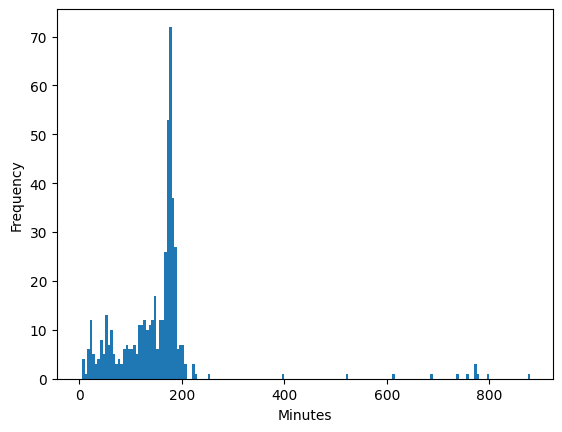

In [127]:
# Some statistics
print(f"Number of meetings:\n{len(ga_index_df)}\n")
print(f"Distribution over bodies:\n{ga_index_df['body'].value_counts()}\n")
print(f"Has transcripts:\n{ga_index_df['hasTranscript'].value_counts()}\n")
# Meeting durations
minutes = pd.to_timedelta(ga_index_df['duration']).dt.total_seconds() / 60
minutes = minutes[minutes > 0]

minutes.plot.hist(bins=range(0, int(minutes.max()) + 5, 5), xlabel="Minutes") # TODO: i get a type error here, how can i fix?

In [128]:
# inspect one transcript
meeting_slug = ga_index_df[ga_index_df["hasTranscript"]].iloc[0]["slug"] + ".json.gz"
SINGLE_MEETING = TRANSCRIPTS / meeting_slug 
print(SINGLE_MEETING)
assert SINGLE_MEETING.exists()

/home/janic/Workspace/Personal/repos/policy-pulse/data/transcripts/ga/c3/81/41.json.gz


In [129]:
import gzip
meeting = MeetingResponse.model_validate_json(gzip.decompress(SINGLE_MEETING.read_bytes()))
print(f"Keys of meeting:{meeting.model_fields_set}") 
# Here we are at the same point as described above, where we showed what the api can offer us!

Keys of meeting:{'disclaimer', 'url', 'transcript', 'video'}


In [130]:
assert meeting.transcript is not None
pprint(meeting.transcript.data[0].paragraphs[0], max_length=2, max_string=80)

Paragraph(
│   sentences=[
│   │   Sentence(text='Colleagues, we will start shortly.', start=942.37, end=944.69, topics=[]),
│   │   Sentence(text='If you take your seats, please.', start=944.69, end=946.05, topics=[]),
│   │   ... +14
│   ]
)

In [131]:
assert meeting.transcript is not None
# Look at a statement

rows = []
for s in meeting.transcript.data:
    text = " ".join(sen.text for p in s.paragraphs for sen in p.sentences)
    rows.append(
        {
            "meeting_id": meeting.video.slug,
            "seq": s.statement_number,
            "start": s.start,
            "affiliaton": s.speaker.affiliation if s.speaker else None,
            "function": s.speaker.function if s.speaker else None,
            "text": text,
            "n_words": len(text.split()),
        }
    )

meeting_df = pd.DataFrame(rows)
meeting_df.head()

,meeting_id,seq,start,affiliaton,function,text,n_words
0,ga/c3/81/41,1,942.37,3rd Committee,Chair,"Colleagues, we will start shortly. If you take...",272
1,ga/c3/81/41,2,1139.32,MNG,None,"Mr. Chair, Mongolia has the honour to introduc...",343
2,ga/c3/81/41,3,1305.52,3rd Committee,Chair,"Thank you, Mongolia. In addition to the delega...",34
3,ga/c3/81/41,4,1318.27,3rd Committee,Secretary,"Thank you, Mr. Chair. If any other countries w...",57
4,ga/c3/81/41,5,1383.82,3rd Committee,Chair,"Thank you, Secretary. A recorded vote has been...",62


<Axes: title={'center': 'Histogram, how often do statements have x words'}, xlabel='Words', ylabel='Frequency'>

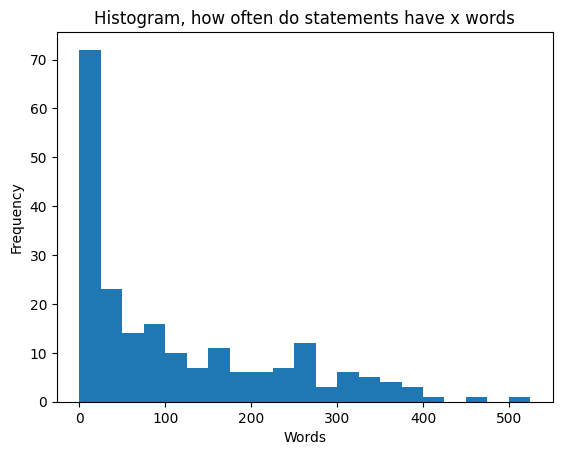

In [132]:
# Distribution of length of that specific meeting
max_words = int(meeting_df["n_words"].max())
meeting_df["n_words"].plot.hist(bins=range(0, max_words + 25, 25), xlabel="Words", title="Histogram, how often do statements have x words")

In [133]:
# Now make one large df out of all meeting records
paths = [TRANSCRIPTS / (slug + ".json.gz") for slug in ga_index_df[ga_index_df["hasTranscript"]]["slug"]]
assert all([f.exists() for f in paths])

rows = []
for f in paths:
    meeting = MeetingResponse.model_validate_json(gzip.decompress(f.read_bytes()))

    assert meeting.transcript is not None

    for s in meeting.transcript.data:
        text = " ".join(sen.text for p in s.paragraphs for sen in p.sentences)
        rows.append(
            {
                "meeting_id": meeting.video.slug,
                "body": meeting.video.body,
                "title": meeting.video.title,
                "session_number": meeting.video.session_number,
                "date": meeting.video.date,
                "pv_symbol": meeting.video.pv_symbol,
                "language": meeting.transcript.language,
                "seq": s.statement_number,
                "start": s.start,
                "affiliation": s.speaker.affiliation if s.speaker else None,
                "function": s.speaker.function if s.speaker else None,
                "text": text,
                "n_words": len(text.split()),
            }
        )

meetings_df = pd.DataFrame(rows)
meetings_df.head()

,meeting_id,body,title,session_number,date,pv_symbol,language,seq,start,affiliation,function,text,n_words
0,ga/c3/81/41,Third Committee,"Third Committee, 41st plenary meeting - Genera...",41st plenary meeting,2026-11-10T00:00:00.000Z,A/C.3/81/SR.41,en,1,942.37,3rd Committee,Chair,"Colleagues, we will start shortly. If you take...",272
1,ga/c3/81/41,Third Committee,"Third Committee, 41st plenary meeting - Genera...",41st plenary meeting,2026-11-10T00:00:00.000Z,A/C.3/81/SR.41,en,2,1139.32,MNG,None,"Mr. Chair, Mongolia has the honour to introduc...",343
2,ga/c3/81/41,Third Committee,"Third Committee, 41st plenary meeting - Genera...",41st plenary meeting,2026-11-10T00:00:00.000Z,A/C.3/81/SR.41,en,3,1305.52,3rd Committee,Chair,"Thank you, Mongolia. In addition to the delega...",34
3,ga/c3/81/41,Third Committee,"Third Committee, 41st plenary meeting - Genera...",41st plenary meeting,2026-11-10T00:00:00.000Z,A/C.3/81/SR.41,en,4,1318.27,3rd Committee,Secretary,"Thank you, Mr. Chair. If any other countries w...",57
4,ga/c3/81/41,Third Committee,"Third Committee, 41st plenary meeting - Genera...",41st plenary meeting,2026-11-10T00:00:00.000Z,A/C.3/81/SR.41,en,5,1383.82,3rd Committee,Chair,"Thank you, Secretary. A recorded vote has been...",62


<Axes: title={'center': 'Histogram, how often do statements have x words (over all meeting records of these two sessions)'}, xlabel='Words', ylabel='Frequency'>

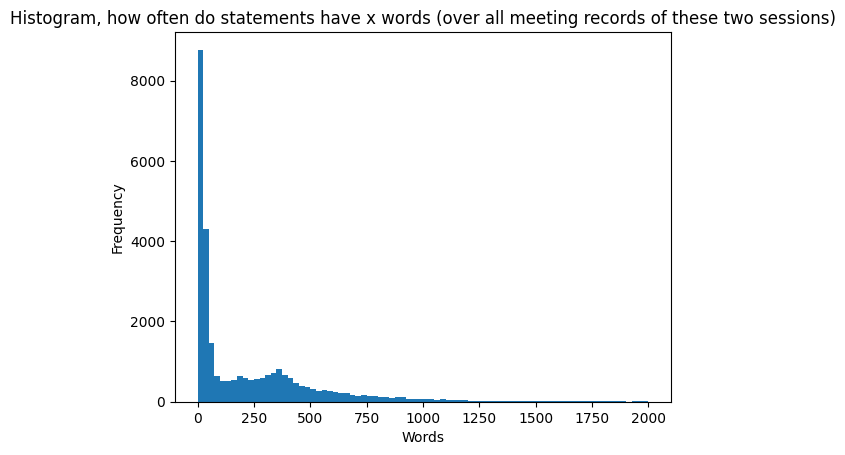

In [134]:
max_words = 2000#int(meetings_df["n_words"].max())
meetings_df["n_words"].plot.hist(bins=range(0, max_words + 25, 25), xlabel="Words", title="Histogram, how often do statements have x words (over all meeting records of these two sessions)")

### 1b. ODS official records

`meeting_records.jsonl` already holds the extracted page text per PV (`symbol`, `title`, `pages`). Session 80 plenary only covers PV.1–6, 17, 18, 36, 37, and there are almost no committee summary records (SR).

Questions to answer while looking at one PV:
- How does a speaker turn start? (e.g. `Mr. X (Country):` / `The President:`)
- What has to go: page headers/footers, the boilerplate on page 1, the "This record contains…" notice?
- Where do agenda items show up ("Agenda item 12")?

In [144]:
# load index.jsonl, filter to GA 80/81
ods_path = DATA / "session80" / "meeting_records.jsonl"
assert ods_path.exists()

rows = []
with open(ods_path) as f:
    for line in f:
        rows.append(MeetingRecordPDF.model_validate_json(line))

print(f"Length of the index file:{len(rows)}")

Length of the index file:13


In [138]:
pprint(rows[0])

MeetingRecordPDF(
│   symbol='A/80/PV.1',
│   title='General Assembly Eightieth session 1st plenary meeting Tuesday, 9 September 2025, 3 p.m. New York',
│   pdf_created="D:20260904113920-04'00'",
│   n_pages=6,
│   n_chars=18062,
│   file='A_80_PV.1.pdf',
│   pages=[
│   │   'United Nations \nA/80/PV.1\n \n \nGeneral Assembly \nEightieth session \n1st plenary meeting \nTuesday, 9 September 2025, 3 p.m. \nNew York \nOfficial Records\n \n \n \nThis record contains the text of speeches delivered in English and of the translation of speeches \ndelivered in other languages.  Corrections should be submitted to the original languages only. \nThey should be incorporated in a copy of the record and sent under the signature of a member of \nthe delegation concerned to the Chief of the Verbatim Reporting Service, room AB-0928 \n(verbatimrecords@un.org). Corrected records will be reissued electronically on the Official \nDocument System of the United Nations (http://documents.un.org). \n \n \n \n25-14392 (E) \n*2514392* \n \n \nPresident:  \nMs. Baerbock ....................................................................................................... (Germany) \nThe meeting was called to order at 3.05 p.m. \nItem 1 of the provisional agenda \nOpening of the session by the President of the General Assembly \nThe President: It is my great pleasure and honour to declare open the eightieth \nsession of the General Assembly and call to order its first plenary meeting. \nItem 2 of the provisional agenda \nMinute of silent prayer or meditation \nThe President: In accordance with rule 62 of the rules of procedure, I invite \nrepresentatives to stand and observe one minute of silent prayer or meditation. \nThe members of the General Assembly observed a minute of silent prayer or \nmeditation. \nStatement by the President \nThe President: The eightieth session of the General Assembly is no ordinary \nsession. Eighty years is longer than the average human lifespan. Normally, this would \nbe a moment for celebration. But are we really in a mood for celebration? \nCan we celebrate while parents in Gaza watch their children starve; while girls \nin Afghanistan are banned from school and denied a normal childhood; while \ngrandfathers in Kharkiv shelter in bathtubs, fearful of drones and missiles; while \nwomen in Darfur hide their daughters from the threat of rape; while Pacific Islanders \nwatch seas rise and waves crash against their homes; and while 808 million people \nremain trapped in extreme poverty, worried about how to simply feed their families? \nInstead of celebrating, we might ask: where is the United Nations that was \ncreated to save us from hell? Where is the United Nations as conflicts spread, as our \nplanet burns, as human rights are trampled? \n',
│   │   'A/80/PV.1 \n09/09/2025\n \n25-14392\n2/6 \n \nOur answer must be clear. We are not giving up; we are here; we see them. Even \nwhen we face setbacks and frustrations, when diplomacy fails us and consensus \neludes us, we will unite to deliver for the people of the world. We will unite to defend \nthe principles of this institution. \nIf girls in Afghanistan or parents in Gaza can wake up in the darkest hours of \nlife and push forward, then so can we. We owe it to them, but we also owe it to \nourselves because there is simply no alternative. The world needs the United Nations. \nIn no way would we be better off without it. This remains the only Organization \ncapable of bringing together every country in the world, the only one capable of acting \non a truly global scale, the only one with worldwide political legitimacy and moral \nauthority. \nYes, our world is in pain, indeed. But imagine how much more pain there would \nbe without the United Nations. Just last year alone, without UNICEF, 26 million \nchildren would not have received an education. Without the World Food Programme, \nnearly 125 million people would have lacked life-saving food assistance. Without the \nOff

In [153]:
dfs = []
for mr in rows:
    cleaned = clean_and_combine(mr.pages)
    df = split_turns(cleaned)
    df["meeting_symbol"] = mr.symbol
    dfs.append(df)

combined_ods = pd.concat(dfs, ignore_index=True)

In [154]:
print(combined_ods["meeting_symbol"].unique())

['A/80/PV.1' 'A/80/PV.18' 'A/80/PV.2' 'A/80/PV.3' 'A/80/PV.4' 'A/80/PV.5']


## 2. Coverage table

One row per meeting: `body`, `session`, `meeting_no`, `has_transcript`, `has_ods`, `source_used`.
Rule: ODS when it exists, transcript otherwise.

Note: the index only knows meetings the site lists. Missing meetings that were never listed won't show up; the highest meeting number per committee is a cheap sanity check.

In [155]:
combined_ods.columns.tolist()

['label',
 'affiliation_raw',
 'spoke_in',
 'agenda_item',
 'text',
 'n_words',
 'meeting_symbol']

In [156]:
meetings_df.columns.tolist()

['meeting_id',
 'body',
 'title',
 'session_number',
 'date',
 'pv_symbol',
 'language',
 'seq',
 'start',
 'affiliation',
 'function',
 'text',
 'n_words']

In [165]:
ods_symbols = combined_ods["meeting_symbol"].unique()
transcript_symbols = meetings_df["pv_symbol"].unique()

pprint(ods_symbols)
pprint(list(transcript_symbols), max_length=10)
in_both = set.intersection(set(ods_symbols), set(transcript_symbols))
pprint(in_both)

array(['A/80/PV.1', 'A/80/PV.18', 'A/80/PV.2', 'A/80/PV.3', 'A/80/PV.4',
│      'A/80/PV.5'], dtype=object)

[
│   'A/C.3/81/SR.41',
│   'A/C.4/81/SR.21',
│   'A/C.5/81/SR.10',
│   'A/81/PV.39',
│   'A/C.3/81/SR.42',
│   'A/C.6/81/SR.40',
│   'A/C.5/81/SR.9',
│   'A/C.4/81/SR.20',
│   'A/81/PV.37',
│   'A/C.6/81/SR.38',
│   ... +364
]

{'A/80/PV.2', 'A/80/PV.5', 'A/80/PV.1', 'A/80/PV.18'}

In [167]:
# create a coverage table
import numpy as np

NUM = r"(\d+)(?:st|nd|rd|th)"
MEETING_NOS_RE = rf"{NUM}(?: and {NUM})? plenary meeting"  # "4th and 5th plenary meeting"


def meeting_symbols(row) -> list[str]:
    """Official symbols of the meeting(s) a transcript covers, from slug + title."""
    m = re.search(MEETING_NOS_RE, row["title"], re.IGNORECASE)  # some titles say "Plenary"
    if m is None:
        return []
    session = re.fullmatch(SLUG_RE, row["slug"]).group(1)
    committee = re.match(r"ga/c(\d)/", row["slug"])
    if committee is None:
        prefix = f"A/{session}/PV"
    else:
        c = committee.group(1)
        prefix = f"A/C.{c}/{session}/{'PV' if c == '1' else 'SR'}"  # only C1 has verbatim records
    return [f"{prefix}.{n}" for n in m.groups() if n]


listed = ga_index_df.assign(symbol=ga_index_df.apply(meeting_symbols, axis=1)).explode("symbol")

transcripts = (
    listed.dropna(subset=["symbol"])
    .groupby("symbol", as_index=False)
    .agg(body=("body", "first"), slugs=("slug", list), has_transcript=("hasTranscript", "any"))
)

ods = pd.read_json(ods_path, lines=True)[["symbol"]]

coverage = transcripts.merge(ods, on="symbol", how="outer", indicator=True)
coverage["has_ods"] = coverage["_merge"] != "left_only"
coverage["has_transcript"] = coverage["has_transcript"].eq(True)  # NaN for ODS-only rows -> False
coverage["source_used"] = np.select(
    [coverage["has_ods"] & coverage["symbol"].str.contains("/PV."), coverage["has_transcript"]],
    ["ods", "transcript"],
    default="none",
)
coverage = coverage.drop(columns="_merge")

In [168]:
coverage.head()

,symbol,body,slugs,has_transcript,has_ods,source_used
0,A/80/PV.1,General Assembly,[ga/80/1],True,True,ods
1,A/80/PV.10,General Assembly,[ga/80/11],True,False,transcript
2,A/80/PV.100,General Assembly,[ga/80/100],True,False,transcript
3,A/80/PV.101,General Assembly,[ga/80/101],True,False,transcript
4,A/80/PV.103,General Assembly,"[ga/80/103/2, ga/80/103/3, ga/80/103]",True,False,transcript


## 3. Statement schema

One row = one speaker turn. Get the core columns working for both sources first, then add the extras as far as they come easily.

| column | type | notes |
|---|---|---|
| `statement_id` | str | e.g. `{meeting_id}#{seq}` |
| `source` | `ods` / `transcript` | |
| `session` | int | |
| `body` | `plenary` / `C1`…`C6` | |
| `meeting_id` | str | PV/SR symbol where known, else slug |
| `date` | date | |
| `seq` | int | order within the meeting |
| `affiliation` | str | ISO3; keep chair/President separate |
| `text` | str | |
| `n_words` | int | |
| *extra* `agenda_item` | str | |
| *extra* `speech_type` | str | general debate / explanation of vote before/after / right of reply |
| *extra* `on_behalf_of` | str | group statements; handle later |
| `url` | str | link back to the record (we show users a window plus this link) |

Suggestion: write one function per source, `parse_transcript(...) -> DataFrame` and `parse_pv(...) -> DataFrame`, that return exactly these columns, then `pd.concat`.
Check: on a meeting that both sources cover (an early session-80 PV), do the speaker sequences match?

In [ ]:
# parse_transcript
meeting_df.columns.tolist()

['meeting_id',
 'body',
 'title',
 'session_number',
 'date',
 'pv_symbol',
 'language',
 'seq',
 'start',
 'affiliation',
 'function',
 'text',
 'n_words']

In [ ]:
SCHEMA = [
    "statement_id", "source", "session", "body", "meeting_id", "date", "seq",
    "affiliation", "text", "n_words", "agenda_item", "speech_type", "on_behalf_of", "function"
]

# 1. Meetings where ODS is the source: drop their transcript statements (otherwise they're in twice)
ods_slugs = set(coverage.loc[coverage["source_used"] == "ods", "slugs"].explode())

# 2. Transcripts in the same shape as ods_df
tr_df = (
    meetings_df[~meetings_df["meeting_id"].isin(ods_slugs)]
    .rename(columns={"session_number": "session"})
    .assign(
        # id from the slug, before meeting_id is overwritten: multi-part meetings
        # (ga/80/103, ga/80/103/2, ...) share one symbol, and seq restarts in every part
        statement_id=lambda d: d["meeting_id"] + "#" + d["seq"].astype(str),
        meeting_id=lambda d: d["pv_symbol"].fillna(d["meeting_id"]),  # symbol where known, else slug
        session=lambda d: d["title"].str.extract(r"(\d+)(?:st|nd|rd|th) session", expand=False).astype(int),
        date=lambda d: pd.to_datetime(d["date"]).dt.tz_localize(None),
        source="transcript",
        agenda_item=None,
        speech_type=None,
        on_behalf_of=None,
    )[SCHEMA]
)
tr_df.head()

NameError: name 'coverage' is not defined

In [17]:
COMMITTEES = {"1": "First", "2": "Second", "3": "Third", "4": "Fourth", "5": "Fifth", "6": "Sixth"}

# meeting date from the record title: "... Tuesday, 23 September 2025, 9 a.m. New York"
ods_meta = pd.read_json(ods_path, lines=True)[["symbol", "title"]]
ods_meta["date"] = pd.to_datetime(
    ods_meta["title"].str.extract(r"(\d{1,2} \w+ \d{4})", expand=False), format="%d %B %Y"
)

parts = combined_ods["meeting_symbol"].str.extract(r"^A/(?:C\.(?P<committee>\d)/)?(?P<session>\d+)/")

ods_df = (
    combined_ods
    .merge(ods_meta[["symbol", "date"]], left_on="meeting_symbol", right_on="symbol")
    .rename(columns={"meeting_symbol": "meeting_id", "affiliation_raw": "affiliation"})
    .assign(
        session=parts["session"].astype(int),
        body=parts["committee"].map(lambda c: f"{COMMITTEES[c]} Committee", na_action="ignore")
            .fillna("General Assembly"),
        seq=lambda d: d.groupby("meeting_id").cumcount() + 1,
        statement_id=lambda d: d["meeting_id"] + "#" + d["seq"].astype(str),
        source="ods",
        speech_type=None,
        on_behalf_of=None,
        function=None
    )[SCHEMA]
)
ods_df.head()

NameError: name 'ods_path' is not defined

In [189]:
# statements = pd.concat([...]); filter to member states
statements = pd.concat([tr_df, ods_df], ignore_index=True)

assert statements["statement_id"].is_unique
statements["source"].value_counts()

source
transcript    28780
ods             232
Name: count, dtype: int64

In [190]:
out_path = DATA / "csvs"
out_path.mkdir(exist_ok=True)
statements.to_csv(out_path / "statements.csv")

## 4. Statistics

Questions worth answering before deciding anything about windows:

- Distribution of `n_words` (overall, per body, per source). How long is the long tail?
- Statements per country: who speaks most / least? Any member states with zero?
- Median length per country
- Statements per agenda item (if filled)
- How much text is formula? ("I thank…", "Mr. President…"): flag sentences/turns, don't delete them
- ODS vs transcript: do lengths differ systematically?

In [4]:
import pandas as pd
import numpy as np
from pathlib import Path

from rich.pretty import pprint

In [5]:
CSVS = Path.cwd().parents[2] / "data" / "csvs"

statements = pd.read_csv(CSVS / "statements.csv")
statements.head()

,Unnamed: 0,statement_id,source,session,body,meeting_id,date,seq,affiliation,text,n_words,agenda_item,speech_type,on_behalf_of
0,0,ga/c3/81/41#1,transcript,81,Third Committee,A/C.3/81/SR.41,2026-11-10,1,3rd Committee,"Colleagues, we will start shortly. If you take...",272.0,NaN,NaN,NaN
1,1,ga/c3/81/41#2,transcript,81,Third Committee,A/C.3/81/SR.41,2026-11-10,2,MNG,"Mr. Chair, Mongolia has the honour to introduc...",343.0,NaN,NaN,NaN
2,2,ga/c3/81/41#3,transcript,81,Third Committee,A/C.3/81/SR.41,2026-11-10,3,3rd Committee,"Thank you, Mongolia. In addition to the delega...",34.0,NaN,NaN,NaN
3,3,ga/c3/81/41#4,transcript,81,Third Committee,A/C.3/81/SR.41,2026-11-10,4,3rd Committee,"Thank you, Mr. Chair. If any other countries w...",57.0,NaN,NaN,NaN
4,4,ga/c3/81/41#5,transcript,81,Third Committee,A/C.3/81/SR.41,2026-11-10,5,3rd Committee,"Thank you, Secretary. A recorded vote has been...",62.0,NaN,NaN,NaN


Text(0.02, 0.5, 'Statements')

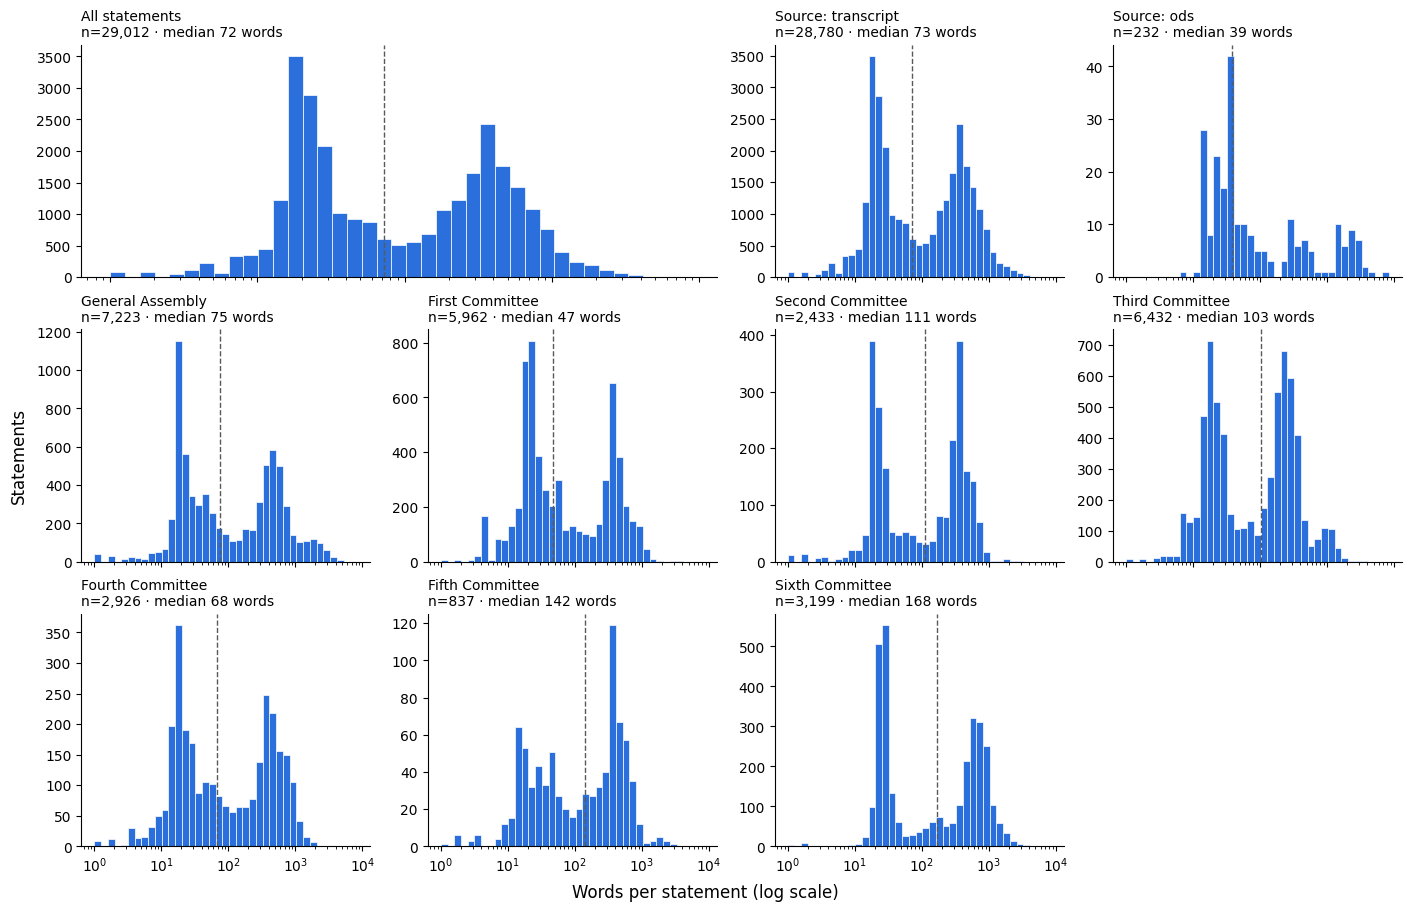

In [6]:
# Look at distribution per 
import matplotlib.pyplot as plt

BODIES = ["General Assembly"] + [f"{n} Committee" for n in ("First", "Second", "Third", "Fourth", "Fifth", "Sixth")]

groups = (
    {"All statements": statements}
    | {f"Source: {s}": statements[statements["source"] == s] for s in ("transcript", "ods")}
    | {b: statements[statements["body"] == b] for b in BODIES}
)

mosaic = [
    ["All statements", "All statements", "Source: transcript", "Source: ods"],
    BODIES[:4],
    BODIES[4:] + ["."],  # "." leaves the cell empty
]
fig, axes = plt.subplot_mosaic(mosaic, figsize=(14, 9), sharex=True, layout="constrained")

# log-spaced bins: lengths run from 1 to several thousand words
bins = np.logspace(0, np.log10(statements["n_words"].max() + 1), 40)

for name, ax in axes.items():
    words = groups[name]["n_words"]
    ax.hist(words, bins=bins, color="#2a6fdb", edgecolor="white", linewidth=0.5)
    median = words.median()
    ax.axvline(median, color="0.35", linestyle="--", linewidth=1)
    ax.set_title(f"{name}\nn={len(words):,} · median {median:.0f} words", fontsize=10, loc="left")
    ax.spines[["top", "right"]].set_visible(False)

axes["All statements"].set_xscale("log")  # sharex applies it to every panel
fig.supxlabel("Words per statement (log scale)")
fig.supylabel("Statements")

In [9]:
# Let's look at countries
member_states = pd.read_csv(CSVS.parent / "member_states.csv")

reading_form = member_states["name_en"].str.replace(r"^(.+) \((.+)\)$", r"\2 \1", regex=True)
name_to_iso = dict(zip(member_states["name_en"], member_states["iso_code"])) | dict(
    zip(reading_form, member_states["iso_code"])
)

In [ ]:
# Fix some by hand
MANUAL_NAMES = {
    'United States of America': "USA",
    'State of Palestine': "PSE",
    'Mr. Luiz Inácio Lula da Silva, President of the Federative Republic of Brazil': "BRA",
    'Mr. Donald J. Trump, President of the United States of America': "USA",
    'Mr. Prabowo Subianto, President of the Republic of Indonesia': "IDN",
    'Mr. Recep Tayyip Erdoğan, President of the Republic of Türkiye': "TUR",
    'Ms. \u2060Dina Ercilia Boluarte Zegarra, President of the Republic of Peru': "PER",
    'His Majesty King Abdullah II ibn Al Hussein, King of the Hashemite Kingdom of Jordan': "JOR",
    'His Excellency Mr. Lee Jae Myung, President of the Republic of Korea': "KOR",
    'His Highness Sheikh Tamim bin Hamad Al Thani, Amir of the State of Qatar': "QAT",
    'Ms. Jennifer Geerlings-Simons, President of the Republic of Suriname': "SUR",
    'His Excellency Mr. Gitanas Nausėda, President of the Republic of Lithuania': "LTU",
    'His Excellency Marcelo Rebelo de Sousa, President of the Portuguese Republic': "PRT",
    'Mr. Yamandú Orsi, President of the Oriental Republic of Uruguay': "URY",
    'Ms. Nataša Pirc Musar, President of the Republic of Slovenia': "SVN",
    'Mr. Kassym-Jomart Tokayev, President of the Republic of Kazakhstan': "KAZ",
    'Mr. Cyril Matamela Ramaphosa, President of the Republic of South Africa': "ZAF",
    'Mr. Shavkat Mirziyoyev, President of the Republic of Uzbekistan': "UZB",
    'Mr. Khurelsukh Ukhnaa, President of Mongolia': "MNG",
    'Mr. Serdar Berdimuhamedov, President of Turkmenistan': "TKM",
    'Mr. Gabriel Boric Font, President of the Republic of Chile': "CHL",
    'Mr. Emomali Rahmon, President of the Republic of Tajikistan': "TJK",
    'Mr. Joseph Aoun, President of the Lebanese Republic': "LBN",
    'Mr. Emmanuel Macron, President of the French Republic': "FRA",
    'Mr. Sadyr Zhaparov, President of the Kyrgyz Republic': "KGZ",
    'Mr. Gustavo Petro Urrego, President of the Republic of Colombia': "COL",
    'Mr. Karol Nawrocki, President of the Republic of Poland': "POL",
    'Mr. Daniel Francisco Chapo, President of the Republic of Mozambique': "MOZ",
    'Mr. Luong Cuong, State President of the Socialist Republic of Viet Nam': "VNM",
    'Mr. João Manuel Gonçalves Lourenço, President of the Republic of Angola': "AGO",
    'Mr. Joseph Nyuma Boakai, President of the Republic of Liberia': "LBR",
    'Mr. Félix-Antoine Tshisekedi Tshilombo, President of the Democratic Republic of the Congo': "COD",
    'Mr. Abdullatif Jamal Rashid, President of the Republic of Iraq': "IRQ",
    'Mr. David Ranibok Adeang, President and Head of State of the Republic of Nauru': "NRU"
}

name_to_iso |= MANUAL_NAMES

is_ods = statements["source"] == "ods"
statements.loc[is_ods, "affiliation"] = (
    statements.loc[is_ods, "affiliation"].map(name_to_iso).fillna(statements.loc[is_ods, "affiliation"])
)
# what didn't match: fix the frequent ones by hand
list(statements.loc[is_ods & ~statements["affiliation"].isin(member_states["iso_code"]), "affiliation"].unique())

[nan, 'Department for General Assembly and Conference Management', 'PSE']

In [18]:
# shortcut: function names as the site uses them; check with statements["function"].value_counts()
CHAIR_FUNCTIONS = {"Chair", "Vice-Chair", "PGA", "Vice-President", "Secretary", "Rapporteur"}

ms_statements = statements[
    statements["affiliation"].isin(member_states["iso_code"])
#    & ~statements["function"].isin(CHAIR_FUNCTIONS)
    & (statements["n_words"] > 2)  # "Malaysia." = chair's call-out attributed to the country
]

per_country = (
    ms_statements.groupby("affiliation")["n_words"]
    .agg(n_statements="size", median_words="median", total_words="sum")
    .reindex(member_states["iso_code"])  # states without statements stay in the table
    .fillna({"n_statements": 0, "total_words": 0})
    .astype({"n_statements": int, "total_words": int})
    .join(member_states.set_index("iso_code")["name_en"])
    .sort_values("n_statements", ascending=False)
)
per_country


,n_statements,median_words,total_words,name_en
iso_code,,,,
RUS,459,357.0,213630,Russian Federation
IRN,364,354.5,162498,Iran (Islamic Republic of)
USA,296,319.5,121229,United States
CUB,270,350.0,117003,Cuba
CHN,238,358.0,101689,China
...,...,...,...,...
BTN,2,1569.5,3139,Bhutan
NRU,2,1932.0,3864,Naoero
GRD,2,2236.0,4472,Grenada


Text(0.0, 1.0, '0 member states without any statement')

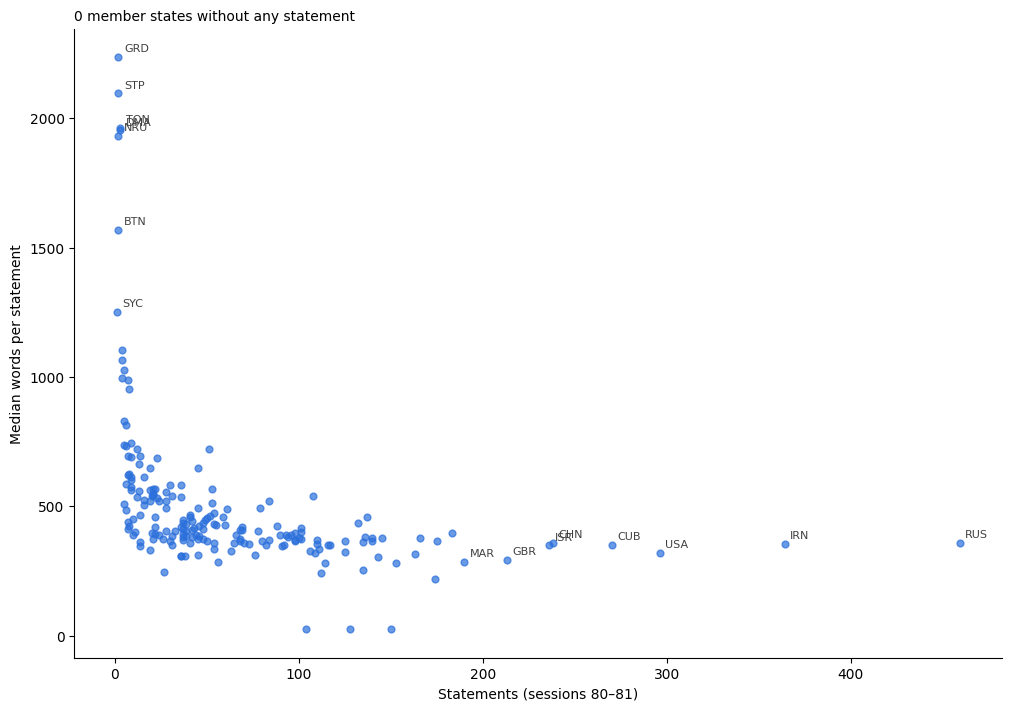

In [19]:


fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
ax.scatter(per_country["n_statements"], per_country["median_words"], s=24, color="#2a6fdb", alpha=0.7)

# label only the extremes, otherwise 193 labels overlap
extremes = pd.concat([
    per_country.nlargest(8, "n_statements"),
    per_country.nlargest(5, "median_words"),
    per_country[per_country["n_statements"] > 0].nsmallest(5, "n_statements"),
]).drop_duplicates()
for iso, row in extremes.iterrows():
    ax.annotate(iso, (row["n_statements"], row["median_words"]), xytext=(4, 4),
                textcoords="offset points", fontsize=8, color="0.25")

ax.set_xlabel("Statements (sessions 80–81)")
ax.set_ylabel("Median words per statement")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"{(per_country['n_statements'] == 0).sum()} member states without any statement", loc="left", fontsize=10)

## 5. Sentences + windows

- One sentence splitter for both sources (e.g. `pysbd` or spaCy's `sentencizer`). Don't use the transcript API's own sentences: ~5% merge several sentences.
- Add a formula flag per sentence.
- Choose the window size from the statistics in section 4. The earlier design for comparison: statements ≥32 words, windows of whole sentences ≤100 words, ~25% overlap, last window anchored to the statement end.
- Output: a `windows` table (`window_id`, `statement_id`, `start_sentence`, `end_sentence`, `text`, `n_words`).

In [ ]:
# Get an example for sentence splitting
example = statements[statements["n_words"].between(80, 150)].iloc[0]
pprint(example)
print(example["text"])

Unnamed: 0                                                     17
statement_id                                       ga/c3/81/41#18
source                                                 transcript
session                                                        81
body                                              Third Committee
meeting_id                                         A/C.3/81/SR.41
date                                                   2026-11-10
seq                                                            18
affiliation                                                   RUS
text            Mr. Chairman, we would like to thank the deleg...
n_words                                                     114.0
agenda_item                                                   NaN
speech_type                                                   NaN
on_behalf_of                                                  NaN
Name: 17, dtype: object

Mr. Chairman, we would like to thank the delegation of Mongolia for introducing the draft resolution, "Literacy for life: Shaping future agendas". We are also fully convinced that education is the best guarantee of prosperity for current and future generations. That's why Russia played an active part in the negotiations, and we support the adoption of the draft today. However, we wish to underscore that the resolution contains references to documents in the negotiations on which we did not participate. cannot be deemed to give rise to any obligations for us. Moreover, we interpret any mention of the term gender and terms derived from it as referring to men and women. I thank you.


In [ ]:
# Get the sentence splitter and show an example
# We use pysbd for performance
# Of course there will be some transcription issues, however we respect this and add disclaimers
import pysbd

segmenter = pysbd.Segmenter(language="en", clean=False)

for i, sentence in enumerate(segmenter.segment(example["text"])):
    print(f"{i:>2} {sentence}")


 0 Mr. Chairman, we would like to thank the delegation of Mongolia for introducing the draft resolution, "Literacy for life: Shaping future agendas". 
 1 We are also fully convinced that education is the best guarantee of prosperity for current and future generations. 
 2 That's why Russia played an active part in the negotiations, and we support the adoption of the draft today. 
 3 However, we wish to underscore that the resolution contains references to documents in the negotiations on which we did not participate. 
 4 cannot be deemed to give rise to any obligations for us. 
 5 Moreover, we interpret any mention of the term gender and terms derived from it as referring to men and women. 
 6 I thank you.


In [27]:
# Parse all statements
def segment_text(text: str) -> list[str]:
    """Split a statement into sentences, without the trailing whitespace pysbd keeps."""
    return [str(s).strip() for s in segmenter.segment(text)]

sentences = (
    statements[["statement_id", "text"]]
    .assign(sentence=lambda d: d["text"].map(segment_text))
    .drop(columns="text")
    .explode("sentence", ignore_index=True)
    .dropna(subset=["sentence"])
)

sentences["sent_idx"] = sentences.groupby("statement_id").cumcount()
sentences["n_words"] = sentences["sentence"].str.split().str.len()

In [3]:
from pathlib import Path

In [4]:
# Save the sentences such that we can continue from here without havign to reprocess
DATA = Path.cwd().parents[2] / "data"

sentences.to_pickle(DATA / "sentences_s80_81.pkl")

NameError: name 'sentences' is not defined

In [42]:
!uv add pandas

Resolved 103 packages in 1ms
Checked 74 packages in 10ms


In [11]:
import pandas as pd
import numpy as np
from pathlib import Path

from rich.pretty import pprint

In [12]:
CSVS = Path.cwd().parents[2] / "data" / "csvs"

In [14]:
statements = pd.read_csv(CSVS / "statements.csv")
statements.head()

,Unnamed: 0,statement_id,source,session,body,meeting_id,date,seq,affiliation,text,n_words,agenda_item,speech_type,on_behalf_of
0,0,ga/c3/81/41#1,transcript,81,Third Committee,A/C.3/81/SR.41,2026-11-10,1,3rd Committee,"Colleagues, we will start shortly. If you take...",272.0,NaN,NaN,NaN
1,1,ga/c3/81/41#2,transcript,81,Third Committee,A/C.3/81/SR.41,2026-11-10,2,MNG,"Mr. Chair, Mongolia has the honour to introduc...",343.0,NaN,NaN,NaN
2,2,ga/c3/81/41#3,transcript,81,Third Committee,A/C.3/81/SR.41,2026-11-10,3,3rd Committee,"Thank you, Mongolia. In addition to the delega...",34.0,NaN,NaN,NaN
3,3,ga/c3/81/41#4,transcript,81,Third Committee,A/C.3/81/SR.41,2026-11-10,4,3rd Committee,"Thank you, Mr. Chair. If any other countries w...",57.0,NaN,NaN,NaN
4,4,ga/c3/81/41#5,transcript,81,Third Committee,A/C.3/81/SR.41,2026-11-10,5,3rd Committee,"Thank you, Secretary. A recorded vote has been...",62.0,NaN,NaN,NaN


In [20]:
# Let's look at countries
member_states = pd.read_csv(CSVS.parent / "member_states.csv")

reading_form = member_states["name_en"].str.replace(r"^(.+) \((.+)\)$", r"\2 \1", regex=True)
name_to_iso = dict(zip(member_states["name_en"], member_states["iso_code"])) | dict(
    zip(reading_form, member_states["iso_code"])
)
# Fix some by hand
MANUAL_NAMES = {
    'United States of America': "USA",
    'State of Palestine': "PSE",
    'Mr. Luiz Inácio Lula da Silva, President of the Federative Republic of Brazil': "BRA",
    'Mr. Donald J. Trump, President of the United States of America': "USA",
    'Mr. Prabowo Subianto, President of the Republic of Indonesia': "IDN",
    'Mr. Recep Tayyip Erdoğan, President of the Republic of Türkiye': "TUR",
    'Ms. \u2060Dina Ercilia Boluarte Zegarra, President of the Republic of Peru': "PER",
    'His Majesty King Abdullah II ibn Al Hussein, King of the Hashemite Kingdom of Jordan': "JOR",
    'His Excellency Mr. Lee Jae Myung, President of the Republic of Korea': "KOR",
    'His Highness Sheikh Tamim bin Hamad Al Thani, Amir of the State of Qatar': "QAT",
    'Ms. Jennifer Geerlings-Simons, President of the Republic of Suriname': "SUR",
    'His Excellency Mr. Gitanas Nausėda, President of the Republic of Lithuania': "LTU",
    'His Excellency Marcelo Rebelo de Sousa, President of the Portuguese Republic': "PRT",
    'Mr. Yamandú Orsi, President of the Oriental Republic of Uruguay': "URY",
    'Ms. Nataša Pirc Musar, President of the Republic of Slovenia': "SVN",
    'Mr. Kassym-Jomart Tokayev, President of the Republic of Kazakhstan': "KAZ",
    'Mr. Cyril Matamela Ramaphosa, President of the Republic of South Africa': "ZAF",
    'Mr. Shavkat Mirziyoyev, President of the Republic of Uzbekistan': "UZB",
    'Mr. Khurelsukh Ukhnaa, President of Mongolia': "MNG",
    'Mr. Serdar Berdimuhamedov, President of Turkmenistan': "TKM",
    'Mr. Gabriel Boric Font, President of the Republic of Chile': "CHL",
    'Mr. Emomali Rahmon, President of the Republic of Tajikistan': "TJK",
    'Mr. Joseph Aoun, President of the Lebanese Republic': "LBN",
    'Mr. Emmanuel Macron, President of the French Republic': "FRA",
    'Mr. Sadyr Zhaparov, President of the Kyrgyz Republic': "KGZ",
    'Mr. Gustavo Petro Urrego, President of the Republic of Colombia': "COL",
    'Mr. Karol Nawrocki, President of the Republic of Poland': "POL",
    'Mr. Daniel Francisco Chapo, President of the Republic of Mozambique': "MOZ",
    'Mr. Luong Cuong, State President of the Socialist Republic of Viet Nam': "VNM",
    'Mr. João Manuel Gonçalves Lourenço, President of the Republic of Angola': "AGO",
    'Mr. Joseph Nyuma Boakai, President of the Republic of Liberia': "LBR",
    'Mr. Félix-Antoine Tshisekedi Tshilombo, President of the Democratic Republic of the Congo': "COD",
    'Mr. Abdullatif Jamal Rashid, President of the Republic of Iraq': "IRQ",
    'Mr. David Ranibok Adeang, President and Head of State of the Republic of Nauru': "NRU"
}

name_to_iso |= MANUAL_NAMES

is_ods = statements["source"] == "ods"
statements.loc[is_ods, "affiliation"] = (
    statements.loc[is_ods, "affiliation"].map(name_to_iso).fillna(statements.loc[is_ods, "affiliation"])
)
# what didn't match: fix the frequent ones by hand
list(statements.loc[is_ods & ~statements["affiliation"].isin(member_states["iso_code"]), "affiliation"].unique())

[nan, 'Department for General Assembly and Conference Management', 'PSE']

In [21]:
# read the sentences again

CSVS = Path.cwd().parents[2] / "data" / "csvs"

statements = pd.read_csv(CSVS / "statements.csv", index_col=0)
statements.head()

sentences = pd.read_pickle(CSVS.parent / "sentences_s80_81.pkl")

In [22]:
import re
# Flag sentences that are about thanking & procedural issues
THANKS_RE = re.compile(r"""
    ^\W*
    (?:(?:Mr\.?|Mister|Madam|Madame|Ms\.?)\s[^,]{1,40},\s*)?        # optional address: "Mr. Chair, "
    (?:on\ behalf\ of\ [^,]{1,80},\s*)?                             # optional "On behalf of the Assembly, "
    (?:(?:I|we|my\ delegation|let\ me|allow\ me\ to)\s+)?
    (?:(?:would|should|also|like|wish|want|to|sincerely|warmly|first|must|begin|by|too|once\ again)\s+)*
    thank(?:s|ing)?\b(?!\s+to\b)                                    # "Thanks to our soldiers" is not a thank-you
""", re.IGNORECASE | re.VERBOSE)



# It can be that sentences with content start with an "I thank...", for this we have this guard in case of long sentences
MAX_THANKS_WORDS = 25

sentences["is_thanks"] = sentences["sentence"].str.contains(THANKS_RE) & (sentences["n_words"] <= MAX_THANKS_WORDS)

sentences[~sentences["is_thanks"]].head(10)

,statement_id,sentence,sent_idx,n_words,is_thanks
0,ga/c3/81/41#1,"Colleagues, we will start shortly.",0,5,False
1,ga/c3/81/41#1,"If you take your seats, please.",1,6,False
2,ga/c3/81/41#1,"Very good, colleagues.",2,3,False
4,ga/c3/81/41#1,The 41st meeting of the Third Committee of the...,4,19,False
5,ga/c3/81/41#1,The documentation before the Committee for thi...,5,37,False
6,ga/c3/81/41#1,"Delegations are also reminded that, in accorda...",6,32,False
7,ga/c3/81/41#1,I would further like to remind delegations tha...,7,24,False
8,ga/c3/81/41#1,The deadline for the submission of amendments ...,8,14,False
9,ga/c3/81/41#1,"I should also like to remind delegations that,...",9,31,False
10,ga/c3/81/41#1,Those additional sponsors will therefore not b...,10,10,False


In [23]:
# Let's focus on member state statements for now

ms_statements = statements[
    statements["affiliation"].isin(member_states["iso_code"])
    & (statements["n_words"] > 2)  # "Malaysia." = chair's call-out attributed to the country
]

ms_statements.head()

,statement_id,source,session,body,meeting_id,date,seq,affiliation,text,n_words,agenda_item,speech_type,on_behalf_of
1,ga/c3/81/41#2,transcript,81,Third Committee,A/C.3/81/SR.41,2026-11-10,2,MNG,"Mr. Chair, Mongolia has the honour to introduc...",343.0,NaN,NaN,NaN
7,ga/c3/81/41#8,transcript,81,Third Committee,A/C.3/81/SR.41,2026-11-10,8,USA,"Thank you, Mr. Chair. The United States suppor...",382.0,NaN,NaN,NaN
9,ga/c3/81/41#10,transcript,81,Third Committee,A/C.3/81/SR.41,2026-11-10,10,PER,"Thank you, Chair. Peru would like to make the ...",391.0,NaN,NaN,NaN
11,ga/c3/81/41#12,transcript,81,Third Committee,A/C.3/81/SR.41,2026-11-10,12,SLV,"Thank you, Chair. As we begin the consideratio...",262.0,NaN,NaN,NaN
15,ga/c3/81/41#16,transcript,81,Third Committee,A/C.3/81/SR.41,2026-11-10,16,IRN,"Thank you, Mr. Chair. The Islamic Republic of ...",169.0,NaN,NaN,NaN


In [24]:
ms_st_ids = ms_statements["statement_id"].unique()
_mask = sentences["statement_id"].map(lambda x: x in ms_st_ids)
ms_sentences = sentences[_mask]
ms_sentences.head()

,statement_id,sentence,sent_idx,n_words,is_thanks
16,ga/c3/81/41#2,"Mr. Chair, Mongolia has the honour to introduc...",0,23,False
17,ga/c3/81/41#2,Literacy is the foundation for lifelong learni...,1,12,False
18,ga/c3/81/41#2,"In an increasingly digital world, it is more e...",2,19,False
19,ga/c3/81/41#2,"Yet, according to UNESCO, an estimated 739 9 m...",3,31,False
20,ga/c3/81/41#2,These figures underscore the urgency of accele...,4,11,False


In [25]:
ms_sentences[~ms_sentences["is_thanks"]]["sentence"].sample(1000).to_csv(CSVS / "example_sentences.csv")

In [26]:
from pydantic import BaseModel, Field, ValidationError

In [27]:
# Windows have no overlap currently! 
MAX_WORDS = 100
OVERLAP = 0.25  # share of MAX_WORDS repeated at the start of the next window


def window_spans(n_words: list[int], max_words: int = MAX_WORDS, overlap: float = OVERLAP) -> list[tuple[int, int]]:
    """(first, last) sentence index of each window over one statement's sentences."""
    spans, start = [], 0
    while True:
        # grow the window sentence by sentence while it fits
        end, total = start, n_words[start]
        while end + 1 < len(n_words) and total + n_words[end + 1] <= max_words:
            end += 1
            total += n_words[end]
        if end == len(n_words) - 1:
            # anchor the last window to the statement end: fill it up backwards instead of leaving a short tail
            while start > 0 and total + n_words[start - 1] <= max_words:
                start -= 1
                total += n_words[start]
            spans.append((start, end))
            return spans
        spans.append((start, end))
        # next window repeats the last sentences of this one, up to overlap * max_words words,
        # but always moves forward by at least one sentence
        next_start, repeated = end + 1, 0
        while next_start - 1 > start and repeated + n_words[next_start - 1] <= overlap * max_words:
            next_start -= 1
            repeated += n_words[next_start]
        start = next_start


assert window_spans([10]) == [(0, 0)]
assert window_spans([150]) == [(0, 0)]                         # one over-long sentence = one window
assert window_spans([40, 40, 40]) == [(0, 1), (1, 2)]          # last window anchored to the end
assert window_spans([30] * 4) == [(0, 2), (1, 3)]
assert window_spans([10] * 20) == [(0, 9), (8, 17), (10, 19)]  # 2 sentences (20 words) overlap

class Window(BaseModel): # Could do sliding windows too here
    window_id: str
    statement_id: str
    start_sentence: int
    end_sentence: int
    text: str  # content only: what we embed and count
    text_full: str  # the contiguous passage incl. formula sentences: what the UI shows
    n_words: int  # content words


def build_windows(sentences: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for statement_id, group in sentences.sort_values("sent_idx").groupby("statement_id", sort=False):
        texts = group["sentence"].tolist()
        is_thanks = group["is_thanks"].tolist()
        content_words = group["n_words"].where(~group["is_thanks"], 0).tolist()  # formula sentences cost 0 words
        for i, (first, last) in enumerate(window_spans(content_words)):
            span = range(first, last + 1)
            n_words = sum(content_words[j] for j in span)
            if n_words == 0:
                continue  # window of formula sentences only
            rows.append(Window(
                window_id=f"{statement_id}#w{i}",
                statement_id=statement_id,
                start_sentence=first,
                end_sentence=last,
                text=" ".join(texts[j] for j in span if not is_thanks[j]),
                text_full=" ".join(texts[j] for j in span),
                n_words=n_words,
            ).model_dump())
    return pd.DataFrame(rows)


windows = build_windows(ms_sentences)

In [28]:
windows.head()

,window_id,statement_id,start_sentence,end_sentence,text,text_full,n_words
0,ga/80/7#79#w0,ga/80/7#79,0,3,"Mr. President, the Islamic Republic of Iran ca...","Thank you, Mr. President. Mr. President, the I...",87
1,ga/80/7#79#w1,ga/80/7#79,4,6,The Islamic Republic of Iran strongly condemns...,The Islamic Republic of Iran strongly condemns...,69
2,ga/80/7#79#w2,ga/80/7#79,5,8,It reminds those who support or remain silent ...,It reminds those who support or remain silent ...,91
3,ga/c3/81/41#12#w0,ga/c3/81/41#12,0,3,As we begin the consideration of the draft res...,"Thank you, Chair. As we begin the consideratio...",71
4,ga/c3/81/41#12#w1,ga/c3/81/41#12,3,5,on the basis of the inherent dignity of all pe...,on the basis of the inherent dignity of all pe...,92


In [29]:
windows["text"].iloc[1]

"The Islamic Republic of Iran strongly condemns the heinous atrocities and continuing genocide in Gaza. It reminds those who support or remain silent in the face of these crimes of their moral and legal responsibility under international law. Iran views the Australian government's unfounded accusations and its undermining of longstanding diplomatic relations between the two countries as being in alignment with the Israeli regime's broader strategy of promoting Iranophobia."

In [30]:
import matplotlib.pyplot as plt
BODIES = ["General Assembly"] + [f"{n} Committee" for n in ("First", "Second", "Third", "Fourth", "Fifth", "Sixth")]

mosaic = [
    ["All windows", "All windows", "Source: transcript", "Source: ods"],
    BODIES[:4],
    BODIES[4:] + ["."],  # "." leaves the cell empty
]


Text(0.02, 0.5, 'Windows')

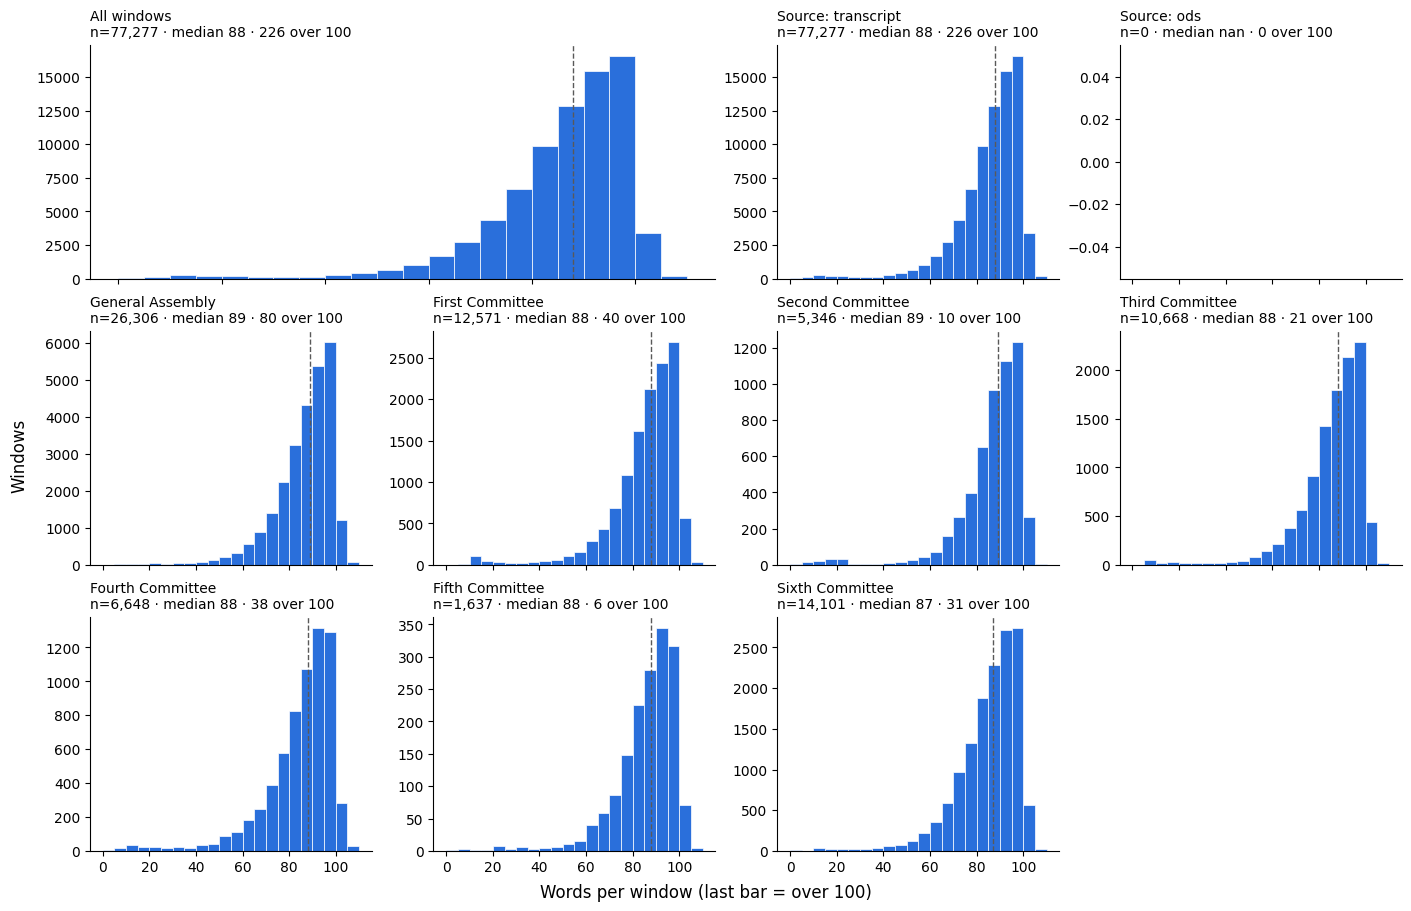

In [31]:
windows_meta = windows.merge(statements[["statement_id", "body", "source"]], on="statement_id", how="left")

groups = (
    {"All windows": windows_meta}
    | {f"Source: {s}": windows_meta[windows_meta["source"] == s] for s in ("transcript", "ods")}
    | {b: windows_meta[windows_meta["body"] == b] for b in BODIES}
)

fig, axes = plt.subplot_mosaic(mosaic, figsize=(14, 9), sharex=True, layout="constrained")

# windows are capped at MAX_WORDS, so a linear axis works; over-long single sentences go into the last bar
bins = range(0, MAX_WORDS + 15, 5)

for name, ax in axes.items():
    words = groups[name]["n_words"]
    n_over = (words > MAX_WORDS).sum()
    ax.hist(words.clip(upper=MAX_WORDS + 5), bins=bins, color="#2a6fdb", edgecolor="white", linewidth=0.5)
    median = words.median()
    ax.axvline(median, color="0.35", linestyle="--", linewidth=1)
    ax.set_title(
        f"{name}\nn={len(words):,} · median {median:.0f} · {n_over} over {MAX_WORDS}",
        fontsize=10, loc="left",
    )
    ax.spines[["top", "right"]].set_visible(False)

fig.supxlabel(f"Words per window (last bar = over {MAX_WORDS})")
fig.supylabel("Windows")

In [32]:
argentina = (
    statements[statements["affiliation"] == "ARG"]
    .sort_values(["date", "meeting_id", "seq"], ascending=[False, True, True])
)

with pd.option_context("display.max_colwidth", 120):
    display(
        argentina[["date", "body", "meeting_id", "n_words", "text"]]
        .head(15)
        .assign(text=lambda d: d["text"].str[:120] + "…")
    )

,date,body,meeting_id,n_words,text
19,2026-11-10,Third Committee,A/C.3/81/SR.41,114.0,"Thank you, Mr. Chair. The Argentine Republic wishes to express its gratitude to the delegation of Mongolia for the w..."
53,2026-11-10,Third Committee,A/C.3/81/SR.41,239.0,"Thank you, Mr. Chair. The Argentine Republic supports women's health and the health of the entire population. For th..."
81,2026-11-10,Third Committee,A/C.3/81/SR.41,231.0,"Thank you very much, Chair. The Argentine Republic supports women's health and the health of the entire population. ..."
431,2026-11-10,Third Committee,A/C.3/81/SR.42,109.0,"Thank you, Chair. Argentina is grateful for the introduction of this resolution, and we value its adoption by consen..."
441,2026-11-10,Third Committee,A/C.3/81/SR.42,72.0,"Thank you, Chair. Argentina appreciates and welcomes the adoption of this draft resolution, and we also welcome any ..."
487,2026-11-10,Third Committee,A/C.3/81/SR.42,107.0,"Thank you, Chair. In relation to draft resolution on strengthening international cooperation on organ donation and t..."
585,2026-11-06,Fourth Committee,A/C.4/81/SR.20,755.0,"Thank you very much, Madam Chair. At the outset, Argentina wishes to express its appreciation thanks to the mission,..."
1130,2026-11-04,Sixth Committee,A/C.6/81/SR.37,1060.0,"Thank you, Chair. With regards to the topic legally non-binding instruments, the Argentine delegation thanks the Spe..."
1303,2026-11-03,Fourth Committee,A/C.4/81/SR.17,562.0,"Thank you, Jim. First of all, the Republic of Argentina would like to express gratitude for the report of the Commit..."
1368,2026-11-03,Sixth Committee,A/C.6/81/SR.35,1093.0,"Thank you very much, Madam Chair. We would like to congratulate Special Rapporteur Mr. August Reinisch on the comple..."


In [33]:
argentina_windows = (
    windows
    .merge(statements[["statement_id", "affiliation", "date", "body", "meeting_id", "seq"]], on="statement_id")
    .query("affiliation == 'ARG'")
    .sort_values(["date", "meeting_id", "seq", "start_sentence"], ascending=[False, True, True, True])
)

with pd.option_context("display.max_colwidth", 200):
    display(argentina_windows[["date", "body", "statement_id", "n_words", "text"]].head(15))

,date,body,statement_id,n_words,text
11,2026-11-10,Third Committee,ga/c3/81/41#20,83,"The Argentine Republic wishes to express its gratitude to the delegation of Mongolia for the work and efforts undertaken as facilitator during the negotiations. Moreover, Argentina would like to m..."
12,2026-11-10,Third Committee,ga/c3/81/41#20,82,"Moreover, Argentina would like to make explicit its dissociation from references to sustainable development, the Sustainable Development Goals, and the 2030 Agenda, and recalls the non-binding nat..."
941,2026-11-10,Third Committee,ga/c3/81/41#54,96,"The Argentine Republic supports women's health and the health of the entire population. For that reason, Argentina considers that it is limiting to highlight just one aspect of women's health that..."
942,2026-11-10,Third Committee,ga/c3/81/41#54,61,"In the Cairo Programme of Action and the Beijing Programme of Action, it was agreed to expressly exclude abortion when it comes to sexual and reproductive health rights. Argentina made a statement..."
943,2026-11-10,Third Committee,ga/c3/81/41#54,74,"Argentina dissociates from references to the 2030 Agenda and recalls the non-binding nature of that instrument, which each state, in full exercise of its sovereignty, has the right to interpret an..."
1299,2026-11-10,Third Committee,ga/c3/81/41#82,95,"The Argentine Republic supports women's health and the health of the entire population. For that reason, Argentina believes that it is limiting to focus on just one aspect of women's health that e..."
1300,2026-11-10,Third Committee,ga/c3/81/41#82,27,"In the Cairo Program of Action and the Beijing Program of Action, it was agreed to expressly exclude abortion when it comes to sexual and reproductive health."
1301,2026-11-10,Third Committee,ga/c3/81/41#82,100,"Argentina made a declaration on Article 1 of the Convention on the Rights of the Child, through which it, regarding the application or protecting the rights of children from the moment of concepti..."
22032,2026-11-10,Third Committee,ga/c3/81/42#28,59,"Argentina is grateful for the introduction of this resolution, and we value its adoption by consensus. Specifically, we wish to highlight the reference to the International Convention for the Prot..."
22033,2026-11-10,Third Committee,ga/c3/81/42#28,87,"Specifically, we wish to highlight the reference to the International Convention for the Protection of All Persons from Enforced Disappearance, and we call for all States who haven't yet done so t..."


In [34]:
for _, w in argentina_windows.head(8).iterrows():
    print(f"{w['date']} · {w['body']} · {w['window_id']} · {w['n_words']} words")
    print(w["text"], "\n")

2026-11-10 · Third Committee · ga/c3/81/41#20#w0 · 83 words
The Argentine Republic wishes to express its gratitude to the delegation of Mongolia for the work and efforts undertaken as facilitator during the negotiations. Moreover, Argentina would like to make explicit its dissociation from references to sustainable development, the Sustainable Development Goals, and the 2030 Agenda, and recalls the non-binding nature of that instrument, which each State, in the full exercise of its sovereignty, has the right to interpret and pursue with liberty, in accordance with its priorities and its national normative framework. 

2026-11-10 · Third Committee · ga/c3/81/41#20#w1 · 82 words
Moreover, Argentina would like to make explicit its dissociation from references to sustainable development, the Sustainable Development Goals, and the 2030 Agenda, and recalls the non-binding nature of that instrument, which each State, in the full exercise of its sovereignty, has the right to interpret and purs

In [35]:
# Continue here by labeling windows by interest factor and if we would want to show them or not!

LABELS = DATA / "window_labels.csv"

sample = (
    windows
    .merge(statements[["statement_id", "affiliation", "date", "body"]], on="statement_id")
    .query("affiliation in ['ARG', 'KEN', 'DEU']")  # pick 2–3 countries you know a bit
    .groupby("affiliation", group_keys=False)
    .apply(lambda d: d.sample(min(len(d), 20), random_state=0))  # 20 per country
    .sample(frac=1, random_state=0)  # shuffle so you don't label one country in a block
)

/tmp/ipykernel_2649653/1617091913.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: d.sample(min(len(d), 20), random_state=0))  # 20 per country


In [46]:
import csv
from datetime import datetime

def label(sample, done):
    todo = sample[~sample["window_id"].isin(done)]
    print(f"{len(done)} labelled, {len(todo)} to go")

    with LABELS.open("a", newline="") as f:
        writer = csv.writer(f)
        if not done:
            writer.writerow(["window_id", "label", "note"])
        for _, w in todo.iterrows():
            print(f"\n{w['affiliation']} · {w['body']} · {datetime.strptime(w['date'],'%Y-%m-%d')} · {w['window_id']}\n")
            print(w["text_full"])
            label = input("show? [y]es / [n]o / [s]kip / [q]uit").strip().lower()
            if label == "q":
                break
            if label == "s":
                continue
            note = input("why? (optional)")
            writer.writerow([w["window_id"], label, note])
            f.flush()  # written at once: nothing lost if the kernel dies

In [43]:
labels = pd.read_csv(LABELS).merge(sample, on="window_id")
labels["label"].value_counts()
labels.groupby("label")["n_words"].describe()  # are "no" windows systematically shorter?

,count,mean,std,min,25%,50%,75%,max
label,,,,,,,,
n,14.0,84.285714,9.562978,68.0,80.25,86.0,89.0,100.0
y,45.0,83.666667,12.051028,45.0,77.00,86.0,91.0,99.0


In [44]:
# Insights after first labeling round
# We should focus on two dimensions when it comes to windows
# a) Information: a country concretely explaining their position (maybe independent of a resolution)
# b) Resolution: does the window reference or talk about a certain resolution (sometimes they just state their position without being super informative)

# We try to build a regex to try to flag these two categories. It will very likely be imperfect but a starting point to label some examples and then we will use the embeddings down the line to figure out if we find some patterns

names = pd.read_csv(CSVS.parent / "member_states.csv")["name_en"].str.replace(r" \(.*\)$", "", regex=True)
COUNTRY = "|".join(sorted(map(re.escape, names), key=len, reverse=True))  # longest first
SUBJECT = rf"(?:we|my\ (?:delegation|country|government)|the\ (?:\w+\ )?delegation(?:\ of\ \w+)?|the\ government\ of\ \w+|{COUNTRY}|the\ argentine\ republic)"
STANCE = r"""(?:support|supports|welcome|welcomes|reaffirm|reaffirms|reiterate|reiterates|reject|rejects|oppose|opposes|condemn|condemns
  |call|calls|urge|urges|recognize|recognizes|concur|concurs|believe|believes|consider|considers|understand|understands
  |remain|remains|stand|stands|are|is|express|expresses|recall|recalls|share|shares|join|joined|joins|insist|insists|regret|regrets
  |deplore|deplores|cannot|will\ not|do\ not|does\ not)"""
# up to two adverbs between subject and verb: "Kenya therefore calls", "Germany fully supports"
POSITION_RE = re.compile(rf"\b{SUBJECT}\s+(?:\w+ly\s+|also\s+|therefore\s+|firmly\s+|fully\s+){{0,2}}{STANCE}\b", re.I | re.X)
CONCERN_RE = re.compile(r"\b(?:deeply\ |gravely\ |seriously\ )?(?:concerned|alarmed|we\ must|must\ immediately|calls?\ (?:up)?on)\b", re.I | re.X)
RESOLUTION_RE = re.compile(r"""\b(?:draft\ resolution|draft\ decision|the\ resolution|this\ resolution|voted?\ (?:in\ favou?r|against)|abstain\w*
  |explanation\ of\ (?:vote|position)|co-?sponsor\w*|core\ group|dissociat\w*|disassociat\w*|consensus|paragraph|A/(?:C\.\d/)?\d+/L\.\d+)\b""", re.I | re.X)

windows = windows.assign(
    pos=lambda d: d["text"].str.contains(POSITION_RE) | d["text"].str.contains(CONCERN_RE),
    res=lambda d: d["text"].str.contains(RESOLUTION_RE),
)

In [48]:
done = set(pd.read_csv(LABELS)["window_id"]) if LABELS.exists() else set()
new = windows[~windows["window_id"].isin(done)].merge(statements[["statement_id", "affiliation", "date", "body"]], on="statement_id")
new = new[~new["affiliation"].isin(["ARG", "KEN", "DEU"])].assign(flagged=lambda d: d["pos"] | d["res"])
sample = (new.groupby("flagged", group_keys=False)
             .apply(lambda d: d.sample(15, random_state=1))  # 15 flagged, 15 unflagged
             .sample(frac=1, random_state=1))

/tmp/ipykernel_2649653/3383441948.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda d: d.sample(15, random_state=1))  # 15 flagged, 15 unflagged


In [50]:
LABELS_V2 = DATA / "window_labels_v2.csv"
FIELDS = ["window_id", "info", "res", "note"]

def ask(prompt: str, valid: set[str]) -> str:
    while (answer := input(prompt).strip().lower()) not in valid:
        print(f"invalid: {answer!r}")
    return answer

def label_windows(sample: pd.DataFrame, path=LABELS_V2) -> None:
    done = set(pd.read_csv(path)["window_id"]) if path.exists() else set()
    todo = sample[~sample["window_id"].isin(done)]
    print(f"{len(done)} labelled, {len(todo)} to go")

    write_header = not path.exists() or path.stat().st_size == 0
    with path.open("a", newline="") as f:
        writer = csv.writer(f)
        if write_header:
            writer.writerow(FIELDS)
        for _, w in todo.iterrows():
            print(f"\n{w['affiliation']} · {w['body']} · {str(w['date'])[:10]} · {w['window_id']}\n")
            print(w["text_full"])
            info = ask("info? [0] none / [1] some / [2] clear position · [s]kip / [q]uit", {"0", "1", "2", "s", "q"})
            if info == "q":
                break
            if info == "s":
                continue
            res = ask("resolution-relevant? [y]es / [n]o", {"y", "n"})
            note = input("why? (optional)")
            writer.writerow([w["window_id"], info, res, note])
            f.flush()

In [54]:
label_windows(sample)

19 labelled, 11 to go

LBY · First Committee · 2026-10-20 · ga/c1/81/15#6#w5

The group stresses the importance of ensuring that the envisaged legally binding international instrument must include a prohibition on the deployment of weapons, be they offensive or defensive, in outer space, a prohibition on any armed attack against or deliberate damage to objects in outer space, a prohibition on the development or testing of any weapons or technologies intended to carry out armed attacks against objects in outer space. It should also establish mechanisms and procedures that allow for the verification of these obligations in a multilateral setting.

UGA · Sixth Committee · 2025-10-07 · ga/c6/80/4#44#w11

We welcome the adoption by consensus of the General Assembly resolution 78/43 and underline the need for this threat to humanity to be addressed within the UN framework and through international cooperation. While stressing that the most effective way of preventing terrorists from acquirin

In [55]:
labels = pd.read_csv(LABELS_V2).merge(sample[["window_id", "pos", "res"]].rename(columns={"res": "res_flag"}), on="window_id")
pd.crosstab(labels["info"], labels["pos"] | labels["res_flag"])  # precision vs. miss rate
pd.crosstab(labels["res"], labels["res_flag"])                   # does the res regex catch your y's?

res_flag,False,True
res,,
n,28,0
y,1,1


In [ ]:
recent_statements = (
    statements[statements["affiliation"].isin(["ARG", "CHE"])]
    .sort_values(["date", "seq"], ascending=False)
    .groupby("affiliation")
    .head(20)  # 20 most recent statements per country
)
recent_windows = windows.merge(recent_statements[["statement_id", "affiliation", "date", "body", "agenda_item"]], on="statement_id")

In [57]:
recent_windows

,window_id,statement_id,start_sentence,end_sentence,text,text_full,n_words,pos,res,affiliation,date,body,agenda_item
0,ga/c3/81/41#20#w0,ga/c3/81/41#20,0,2,The Argentine Republic wishes to express its g...,"Thank you, Mr. Chair. The Argentine Republic w...",83,False,True,ARG,2026-11-10,Third Committee,NaN
1,ga/c3/81/41#20#w1,ga/c3/81/41#20,2,4,"Moreover, Argentina would like to make explici...","Moreover, Argentina would like to make explici...",82,True,True,ARG,2026-11-10,Third Committee,NaN
2,ga/c3/81/41#54#w0,ga/c3/81/41#54,0,3,The Argentine Republic supports women's health...,"Thank you, Mr. Chair. The Argentine Republic s...",96,True,False,ARG,2026-11-10,Third Committee,NaN
3,ga/c3/81/41#54#w1,ga/c3/81/41#54,4,5,In the Cairo Programme of Action and the Beiji...,In the Cairo Programme of Action and the Beiji...,61,False,False,ARG,2026-11-10,Third Committee,NaN
4,ga/c3/81/41#54#w2,ga/c3/81/41#54,6,8,Argentina dissociates from references to the 2...,Argentina dissociates from references to the 2...,74,True,True,ARG,2026-11-10,Third Committee,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
221,ga/c4/81/17#6#w2,ga/c4/81/17#6,7,10,Argentina considers it fundamental to continue...,Argentina considers it fundamental to continue...,100,True,False,ARG,2026-11-03,Fourth Committee,NaN
222,ga/c4/81/17#6#w3,ga/c4/81/17#6,11,12,Multilingualism must lead to an effective dail...,Multilingualism must lead to an effective dail...,65,True,False,ARG,2026-11-03,Fourth Committee,NaN
223,ga/c4/81/17#6#w4,ga/c4/81/17#6,13,14,"With this in mind, we believe it is important ...","With this in mind, we believe it is important ...",74,True,False,ARG,2026-11-03,Fourth Committee,NaN
224,ga/c4/81/17#6#w5,ga/c4/81/17#6,15,16,"Bearing this in mind, we believe it is essenti...","Bearing this in mind, we believe it is essenti...",88,True,False,ARG,2026-11-03,Fourth Committee,NaN


In [ ]:
def print_statement_windows(statement_id: str, first_only=False) -> None:
    sents = ms_sentences[ms_sentences["statement_id"] == statement_id].set_index("sent_idx")
    for _, w in windows[windows["statement_id"] == statement_id].iterrows():
        print(f"── {w['window_id']} · sentences {w['start_sentence']}–{w['end_sentence']} · {w['n_words']} words")
        for i in range(w["start_sentence"], w["end_sentence"] + 1):
            marker = "  (formula)" if sents.at[i, "is_thanks"] else ""
            print(f"  {i:>3} {sents.at[i, 'sentence']}{marker}")
        print()
        if first_only:
            break

print_statement_windows(recent_statements["statement_id"].iloc[0])

── ga/c3/81/41#207#w0 · sentences 0–4 · 99 words
    0 Thank you, Mr. Chair.  (formula)
    1 Switzerland unequivocally condemns all forms of racism, racial discrimination, xenophobia, and related intolerance, including Nazism and neo-Nazism.
    2 These ideologies are incompatible with human rights and fundamental freedoms, and their glorification is a serious threat to social cohesion and peace.
    3 Switzerland firmly rejects antisemitism and all forms of intolerance based on religion or belief, and takes measures in accordance with international law to combat incitement to discrimination, hostility, or violence.
    4 We also recall that all states have obligations to respect and protect human rights, the human rights of every individual on their territory or under their jurisdiction without any discrimination.

── ga/c3/81/41#207#w1 · sentences 5–8 · 98 words
    5 The resolution before us contains important elements for the fight against racism and hatred, including recognising 

In [ ]:
print_statement_windows(recent_statements["statement_id"].iloc[1])

── ga/c3/81/42#84#w0 · sentences 0–1 · 81 words
    0 Thank you, Chair.  (formula)
    1 In relation to draft resolution on strengthening international cooperation on organ donation and transplantation to prevent and combat trafficking in persons for the purpose of organ removal and trafficking in human organs, Argentina recalls that following the 16th of March 2026, We are no longer a member of the WHO, and therefore we disassociate ourselves from the paragraphs referring to this body insofar as this could be interpreted as a commitment to participation or adhesion to its programs, policies, or recommendations.

── ga/c3/81/42#84#w1 · sentences 2–3 · 20 words
    2 And we reaffirm that the definition and implementation of health policy falls to states in the exercise of their sovereignty.
    3 I thank you.  (formula)



In [60]:
print_statement_windows(recent_statements["statement_id"].iloc[2])

── ga/c3/81/41#82#w0 · sentences 0–4 · 95 words
    0 Thank you very much, Chair.  (formula)
    1 The Argentine Republic supports women's health and the health of the entire population.
    2 For that reason, Argentina believes that it is limiting to focus on just one aspect of women's health that excludes the main causes of death of women, including cardiac diseases, heart disease, stroke, Alzheimer's and other forms of dementia, as well as pulmonary diseases.
    3 Having said that, a comprehensive health approach should be adopted.
    4 The government of Argentina understands sexual and reproductive health rights as defined in Article 16E of the Convention on the Elimination of All Forms of Discrimination Against Women.

── ga/c3/81/41#82#w1 · sentences 5–5 · 27 words
    5 In the Cairo Program of Action and the Beijing Program of Action, it was agreed to expressly exclude abortion when it comes to sexual and reproductive health.

── ga/c3/81/41#82#w2 · sentences 6–8 · 100 words
 

In [62]:
import numpy as np
from fastembed import TextEmbedding

model = TextEmbedding("BAAI/bge-small-en-v1.5")  # same model as the session 81 embeddings; downloads ~130 MB on first use

recent_windows = recent_windows.reset_index(drop=True)  # row i ↔ vectors[i]
vectors = np.array(list(model.embed(recent_windows["text"].tolist())))
vectors /= np.linalg.norm(vectors, axis=1, keepdims=True)  # normalised: dot product = cosine similarity
vectors.shape

/home/janic/Workspace/Personal/repos/policy-pulse/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-11-19 14:30:08.046 | INFO     | fastembed.common.model_management:download_files_from_huggingface:375 - Qdrant/bge-small-en-v1.5-onnx-Q is not usable in /tmp/fastembed_cache, loading qdrant/bge-small-en-v1.5-onnx-q, cached from the same repo by an older fastembed version.


(226, 384)

In [63]:
def centroid_sim(group: pd.DataFrame) -> pd.Series:
    v = vectors[group.index]
    c = v.mean(axis=0)
    return pd.Series(v @ (c / np.linalg.norm(c)), index=group.index)

recent_windows["centroid_sim"] = (
    recent_windows.groupby("statement_id", group_keys=False)[["text"]].apply(centroid_sim)
)
best = recent_windows.loc[recent_windows.groupby("statement_id")["centroid_sim"].idxmax()]

── ARG · Third Committee · 2026-11-10 · ga/c3/81/41#20#w0 (2 windows, sim 0.96)
The Argentine Republic wishes to express its gratitude to the delegation of Mongolia for the work and efforts undertaken as facilitator during the negotiations. Moreover, Argentina would like to make explicit its dissociation from references to sustainable development, the Sustainable Development Goals, and the 2030 Agenda, and recalls the non-binding nature of that instrument, which each State, in the full exercise of its sovereignty, has the right to interpret and pursue with liberty, in accordance with its priorities and its national normative framework. 

── ARG · Third Committee · 2026-11-10 · ga/c3/81/42#84#w0 (2 windows, sim 0.89)
In relation to draft resolution on strengthening international cooperation on organ donation and transplantation to prevent and combat trafficking in persons for the purpose of organ removal and trafficking in human organs, Argentina recalls that following the 16th of March